# Stage 1 Data Analysis

### Imports

In [62]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory
from scipy.signal import savgol_filter

### Check on Topics

In [63]:
with open("data-real/stage-1-test-left-1-1/stage-1-test-left-1-1.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   33
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/tf                                      tf2_msgs/msg/TFMessage                   1179
/tf_static                               tf2_msgs/msg/TFMessage                   1
/vicon/athena/athena                     geometry_msgs/msg/PoseStamped            1177
/sensors/imu/raw                         sensor_msgs/msg/Imu                      353
/sensors/servo_position_command          std_msgs/msg/Float64                     48
/commands/motor/speed                    std_msgs/msg/Float64                     48
/commands/servo/position                 std_msgs/msg/Float64                     48
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 47


### Check on Vicon Datapoints

stage-1-test-left-1-1: 1177 Msg (0 deleted) [athena]
stage-1-test-left-1-2: 1414 Msg (0 deleted) [athena]
stage-1-test-left-1-3: 1384 Msg (0 deleted) [athena]
stage-1-test-left-3-1: 2330 Msg (0 deleted) [athena]
stage-1-test-left-3-2: 1135 Msg (386 deleted) [athena]
stage-1-test-left-3-3: 1416 Msg (0 deleted) [athena]
stage-1-test-left-4-1-rear-axle: 1469 Msg (180 deleted) [athena_with_wheel_tracker]
stage-1-test-left-4-2-rear-axle: 1607 Msg (244 deleted) [athena_with_wheel_tracker]
stage-1-test-left-4-3-rear-axle: 1213 Msg (59 deleted) [athena_with_wheel_tracker]
stage-1-test-right-1-1: 1425 Msg (0 deleted) [athena]
stage-1-test-right-1-2: 1453 Msg (1 deleted) [athena]
stage-1-test-right-1-3: 1546 Msg (0 deleted) [athena]
stage-1-test-right-3-1: 1068 Msg (434 deleted) [athena]
stage-1-test-right-3-2: 1372 Msg (422 deleted) [athena]
stage-1-test-right-3-3: 1023 Msg (544 deleted) [athena]
stage-1-test-right-4-1-rear-axle: 1088 Msg (235 deleted) [athena_with_wheel_tracker]
stage-1-test-r

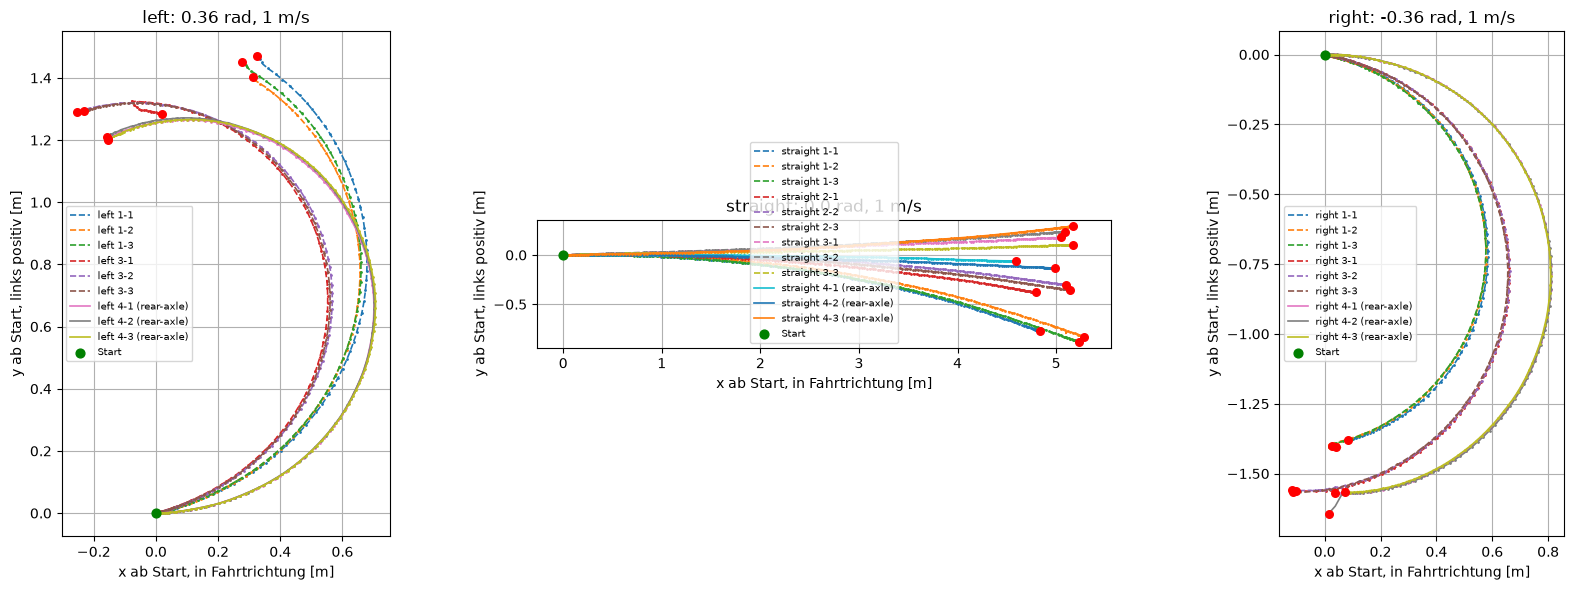

In [64]:
rootdir = "data-real/"
n = 5
max_speed = 5.0
groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}
VICON_TOPICS = [
    "/vicon/athena/athena",
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker",
]
YAW_OFFSET = {                                   # Fahrzeug-Yaw = Vicon-Yaw + Offset
    "/vicon/athena/athena": 0.0,
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker": np.pi / 2,
}
COLS = ["t", "t_log", "px", "py", "pz", "qx", "qy", "qz", "qw"]


def list_topics(path):
    with open(path, "rb") as f:
        summary = make_reader(f).get_summary()
    return sorted(ch.topic for ch in summary.channels.values()) if summary else []


def pick_topic(path):
    topics = list_topics(path)
    for t in VICON_TOPICS:
        if t in topics:
            return t
    print(f"  kein bekanntes Vicon-Topic in {os.path.basename(path)}: "
          f"{[t for t in topics if 'vicon' in t]}")
    return None


def load_vicon(path, topic):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for schema, channel, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p = msg.pose.position
            q = msg.pose.orientation
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,  # Vicon-Zeit
                "t_log": message.log_time / 1e9,                               # Aufnahmezeit
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    if not rows:
        print(f"  keine Daten auf {topic} in {os.path.basename(path)}")
        return pd.DataFrame(columns=COLS)
    return pd.DataFrame(rows).sort_values("t").reset_index(drop=True)


def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3):
    if df.empty:
        return df

    # remove tracking errors by setting them to the origin
    at_origin = (df["px"].abs() < origin_eps) & (df["py"].abs() < origin_eps) & (df["pz"].abs() < origin_eps)
    df = df[~at_origin].reset_index(drop=True)
    if df.empty:
        return df

    # remove outliers via speed
    t = df["t"].to_numpy()
    x = df["px"].to_numpy()
    y = df["py"].to_numpy()

    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        dist = np.hypot(x[i] - x[last], y[i] - y[last])
        if dist <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)


def cut_at_gap(df, max_gap=0.2):
    if df.empty:
        return df
    dt = df["t"].diff().to_numpy()
    gaps = np.where(dt > max_gap)[0]
    if len(gaps):
        df = df.iloc[:gaps[0]]
    return df.reset_index(drop=True)


def quat_to_yaw(df):
    qw, qx, qy, qz = (df[k].to_numpy() for k in ["qw", "qx", "qy", "qz"])
    return np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))


def vehicle_yaw(df, topic):
    return quat_to_yaw(df) + YAW_OFFSET.get(topic, 0.0)


def align_start(df, topic, n0=20):
    """Start auf (0,0) schieben und Fahrzeug-Startausrichtung auf +x drehen."""
    yaw = vehicle_yaw(df, topic)
    yaw0 = np.arctan2(np.sin(yaw[:n0]).mean(), np.cos(yaw[:n0]).mean())  # Kreismittel
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["ax"] = c * dx - s * dy
    out["ay"] = s * dx + c * dy
    return out


dfs = {g: {} for g in groups}
topic_of = {}                                   # welcher Lauf mit welchem Vicon-Objekt
for subdir, dirs, files in os.walk(rootdir):
    for file in files:
        if not file.endswith(".mcap"):
            continue
        name = os.path.splitext(file)[0]

        m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)(?:-([a-z][\w-]*))?$", name)
        if not m:
            print(f"übersprungen: {name}")
            continue
        group, run, tag = m.group(1), m.group(2), m.group(3)
        if tag:
            run = f"{run} ({tag})"              # z. B. "4-1 (rear-axle)"

        path = os.path.join(subdir, file)
        topic = pick_topic(path)
        if topic is None:
            continue

        df = load_vicon(path, topic)
        n_before = len(df)
        df = remove_jumps(df, max_speed=max_speed)
        df = cut_at_gap(df, max_gap=0.2)
        print(f"{name}: {len(df)} Msg ({n_before - len(df)} deleted) [{topic.split('/')[2]}]")

        if not df.empty:
            dfs[group][run] = df
            topic_of[(group, run)] = topic

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10.colors

for ax, group in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[group])):
        df = align_start(dfs[group][run], topic_of[(group, run)])
        c = colors[i % len(colors)]
        ls = "-" if "rear-axle" in run else "--"
        ax.plot(df["ax"], df["ay"], ls, color=c, linewidth=1.2, label=f"{group} {run}")
        ax.plot(df["ax"][::n], df["ay"][::n], "o", color=c, markersize=1)
        ax.scatter(df["ax"].iloc[-1], df["ay"].iloc[-1], color="red", s=30, zorder=3)
    ax.scatter(0, 0, color="green", s=40, zorder=4, label="Start")

    ax.set_title(titles[group])
    ax.set_xlabel("x ab Start, in Fahrtrichtung [m]")
    ax.set_ylabel("y ab Start, links positiv [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

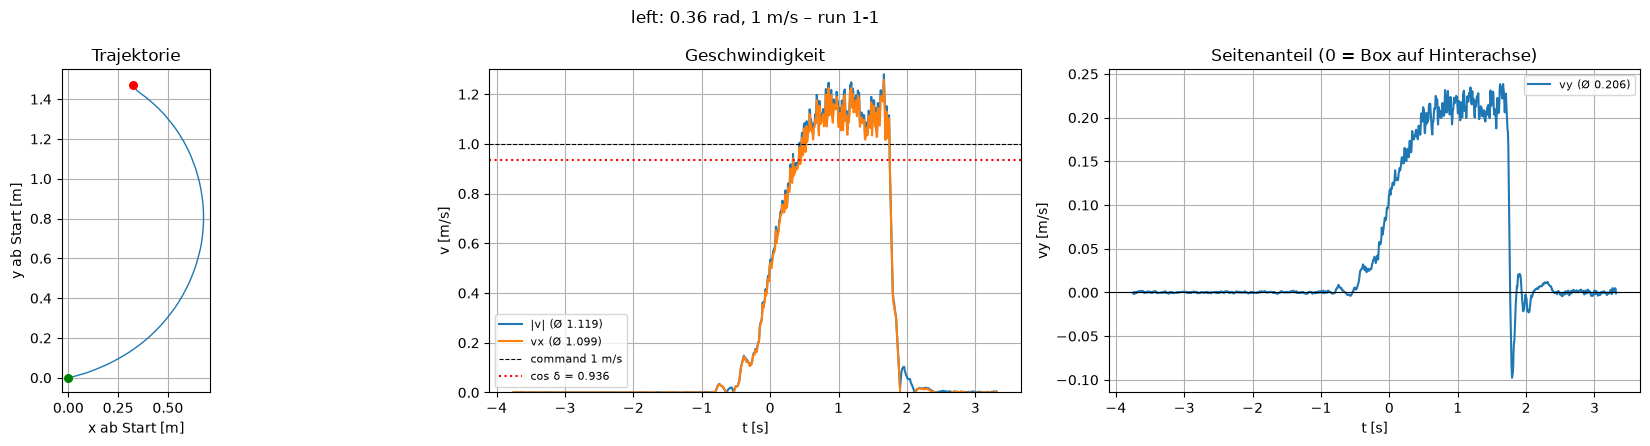

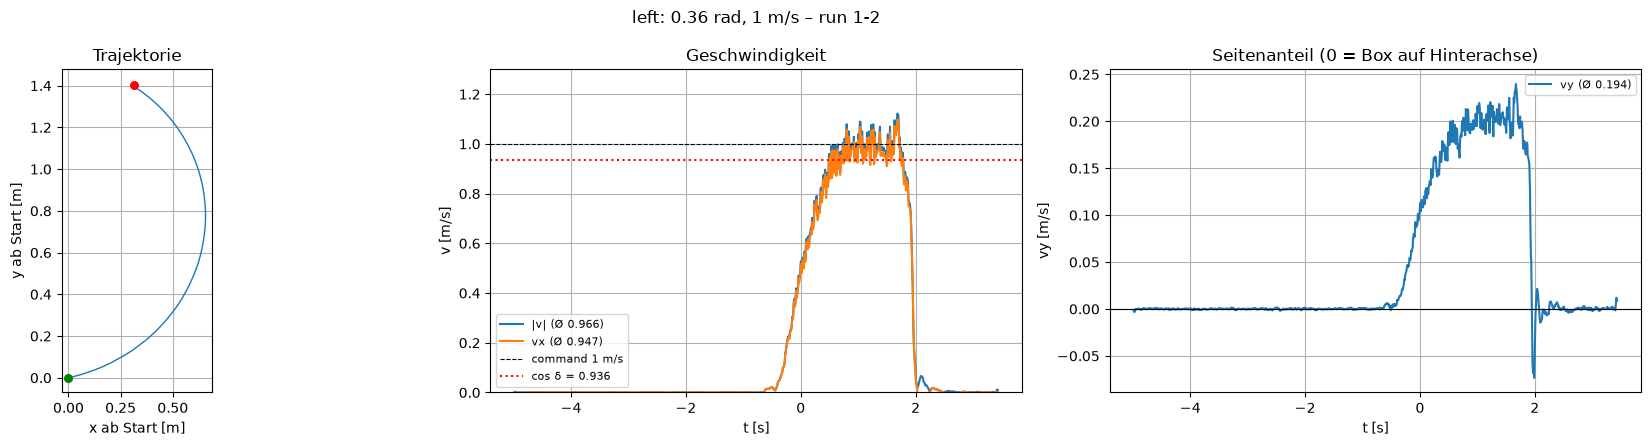

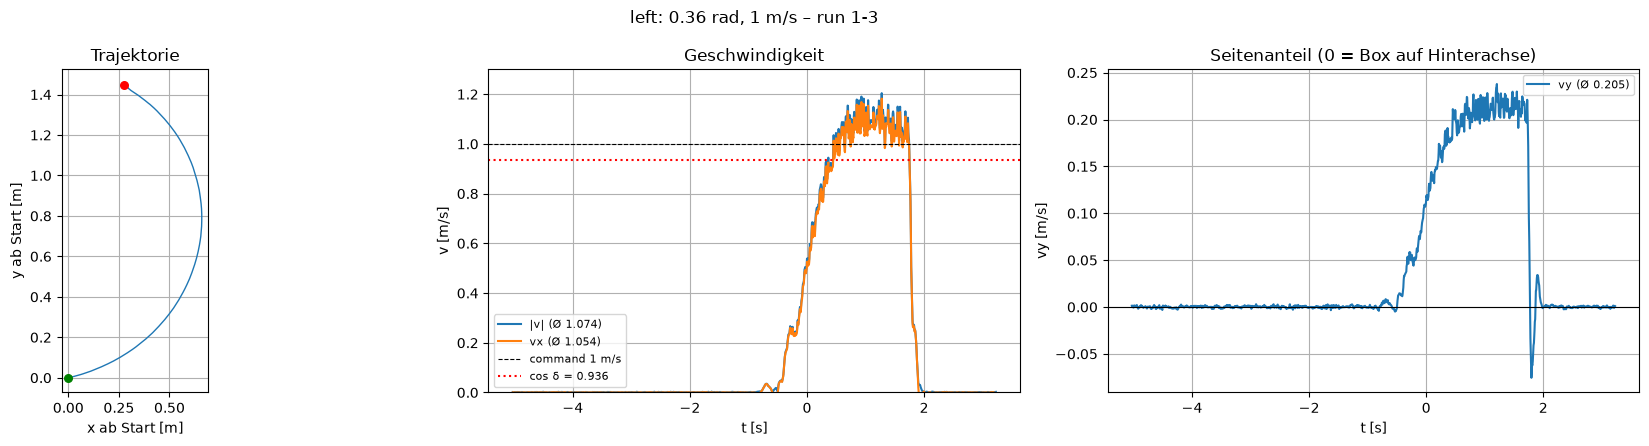

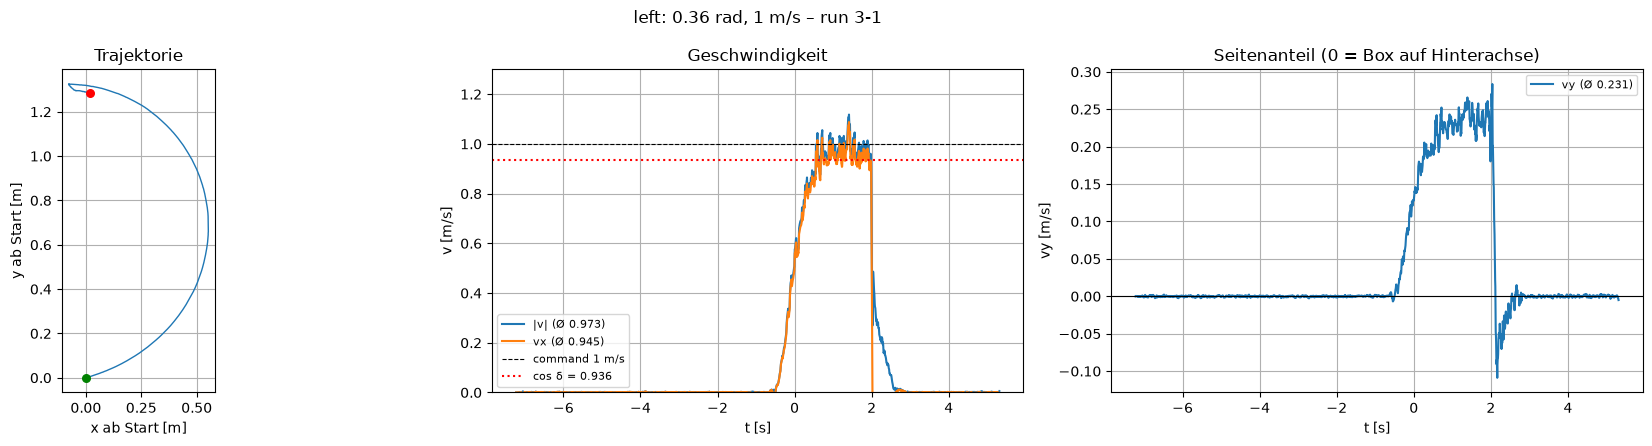

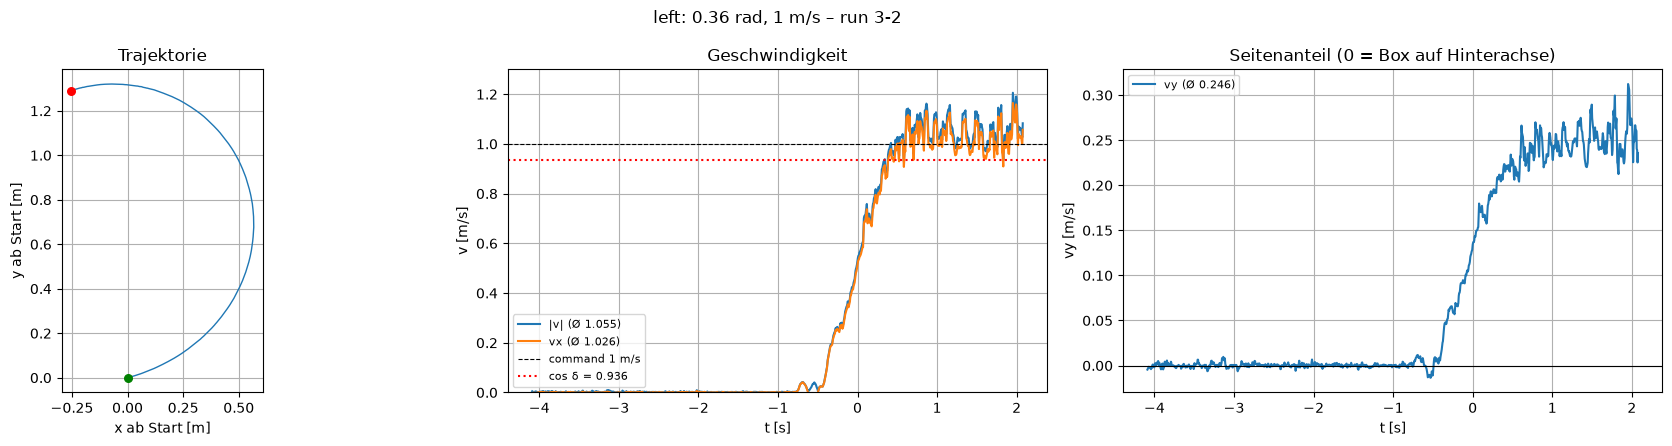

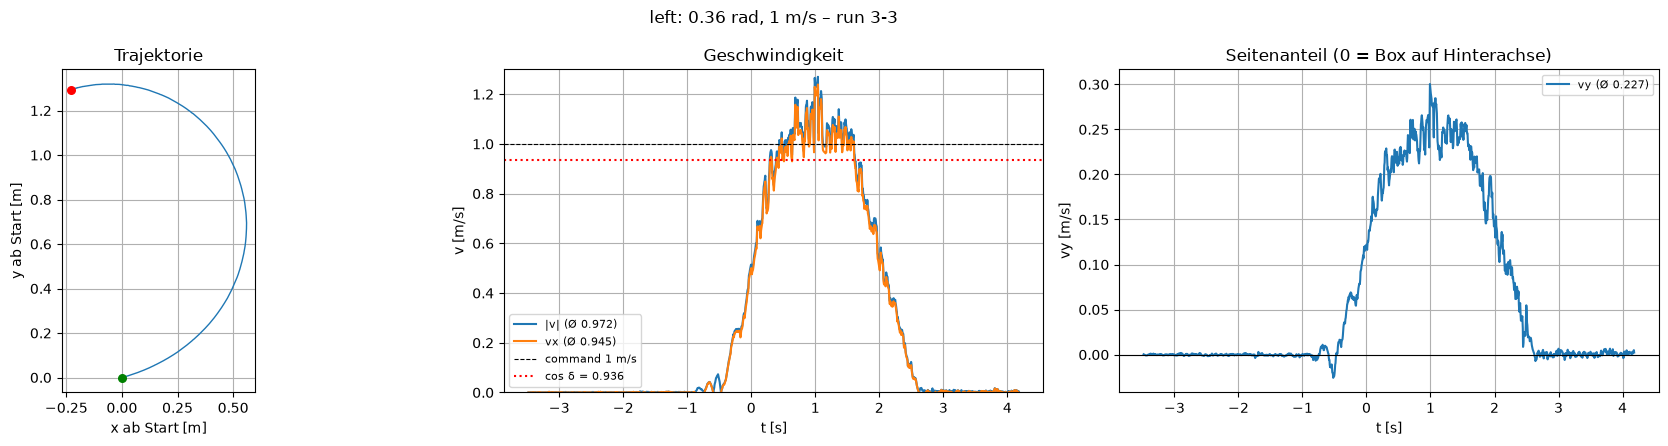

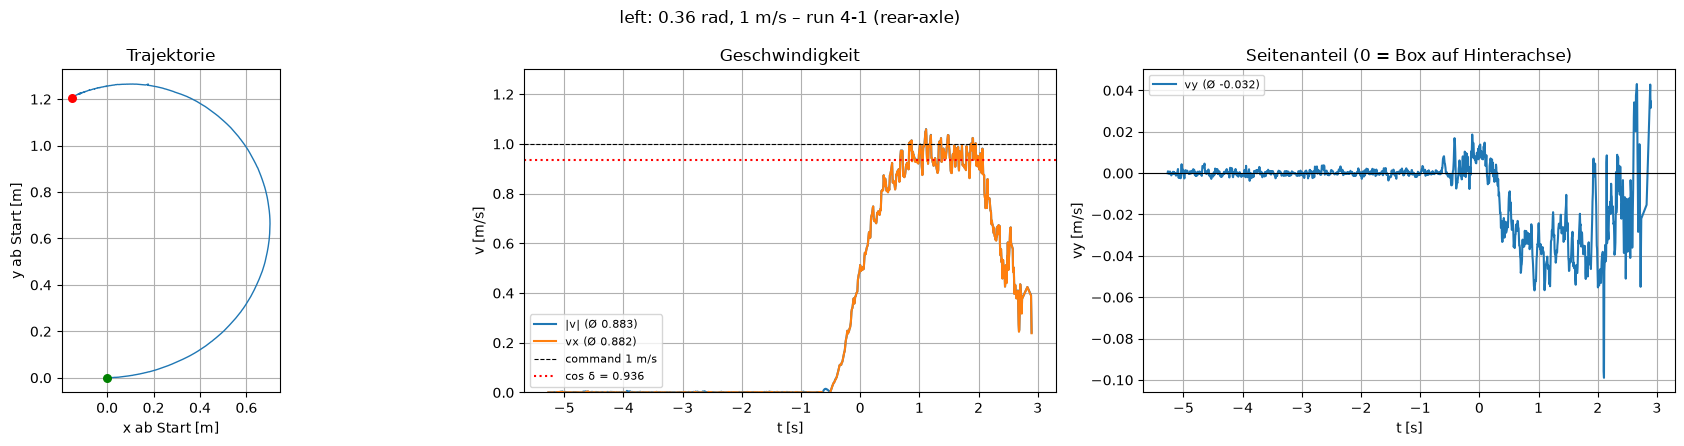

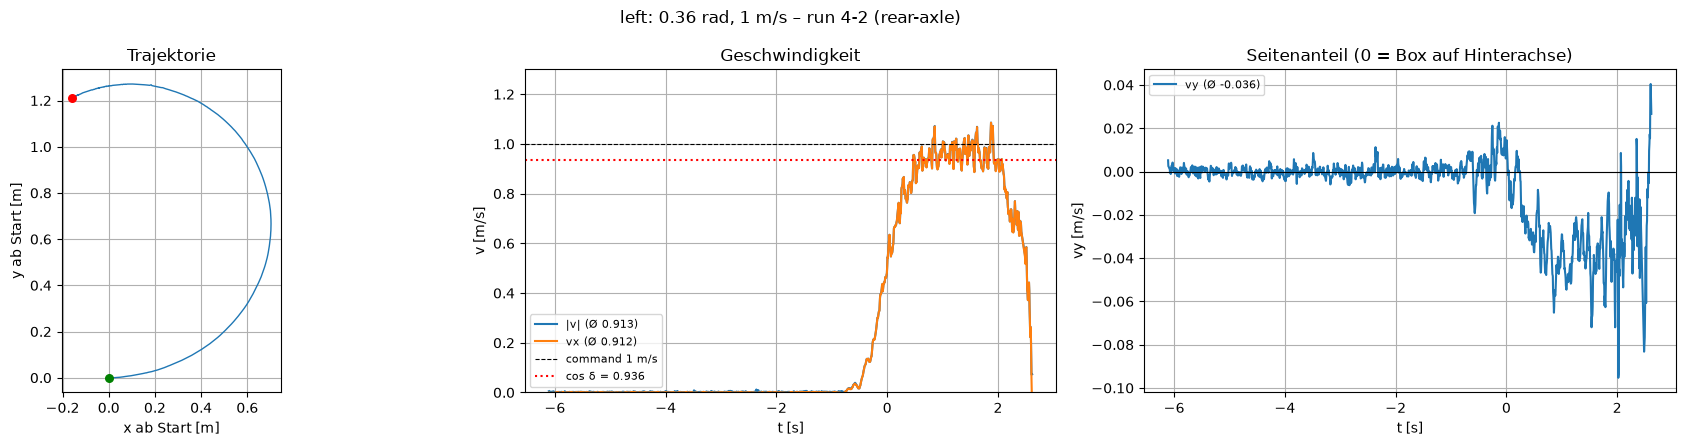

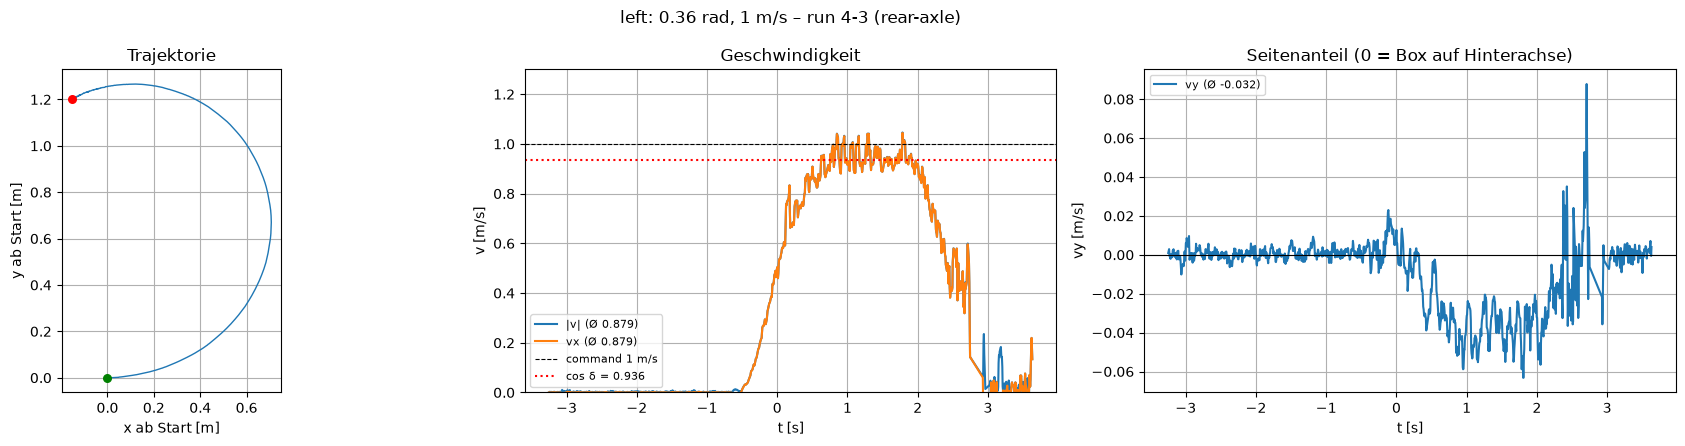

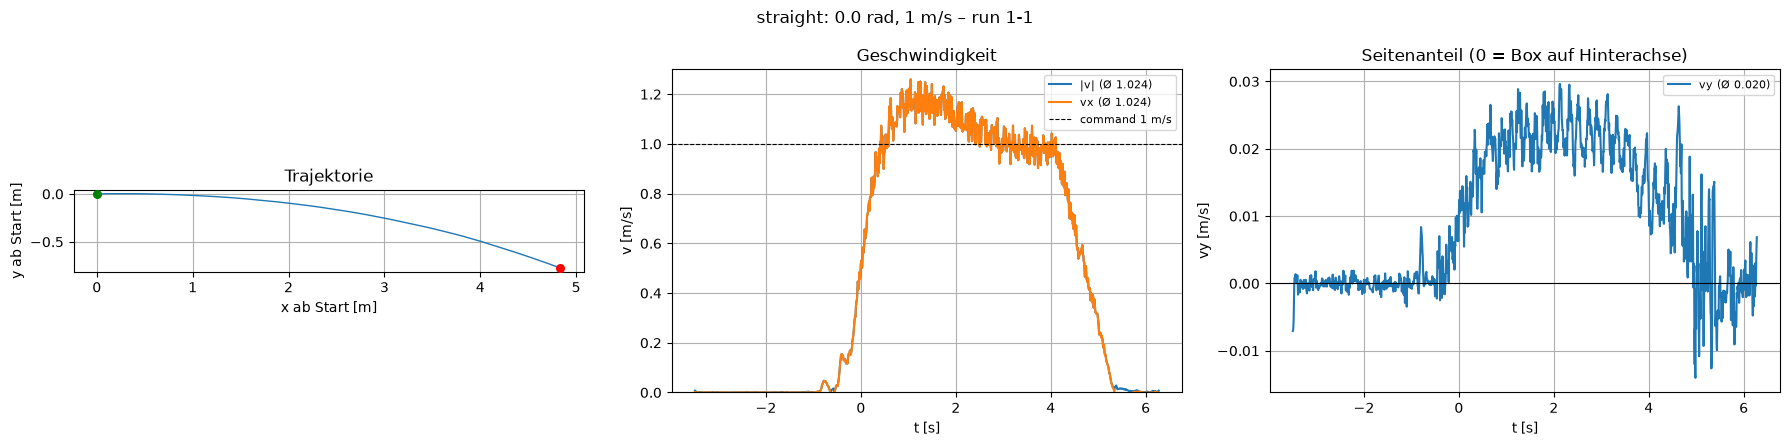

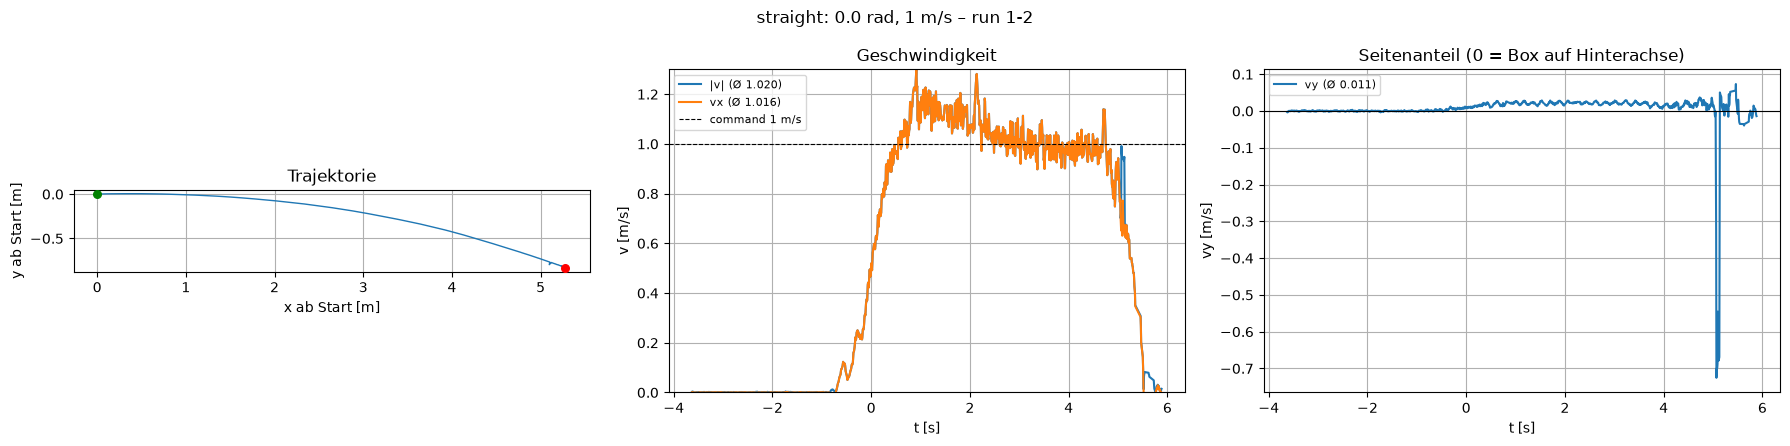

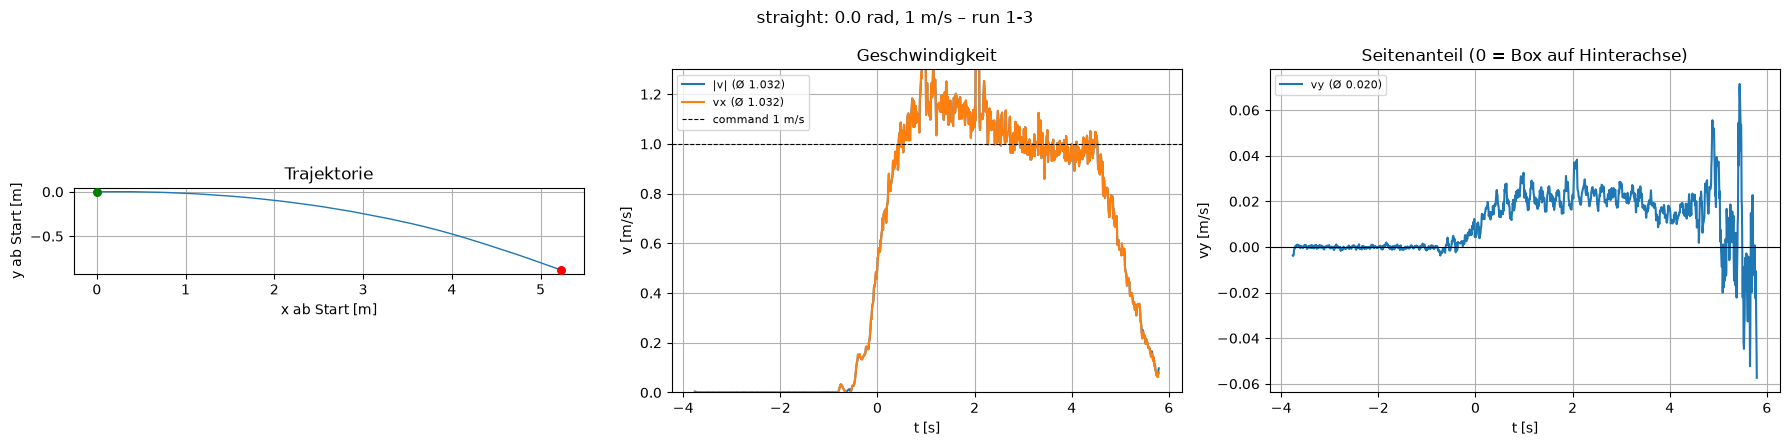

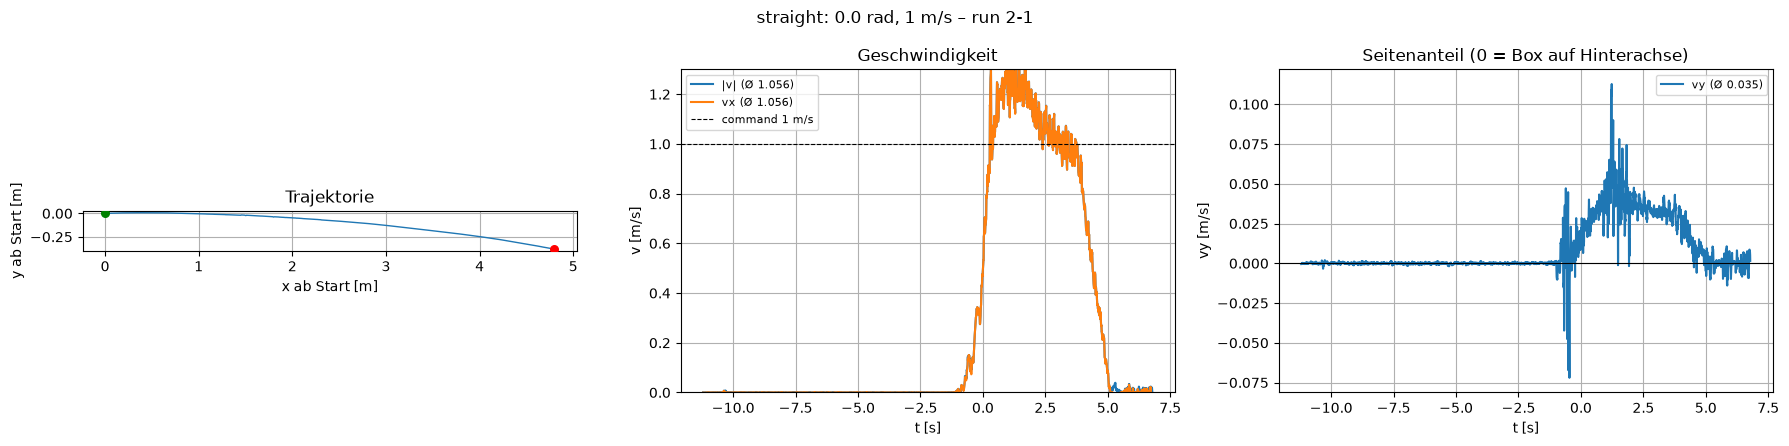

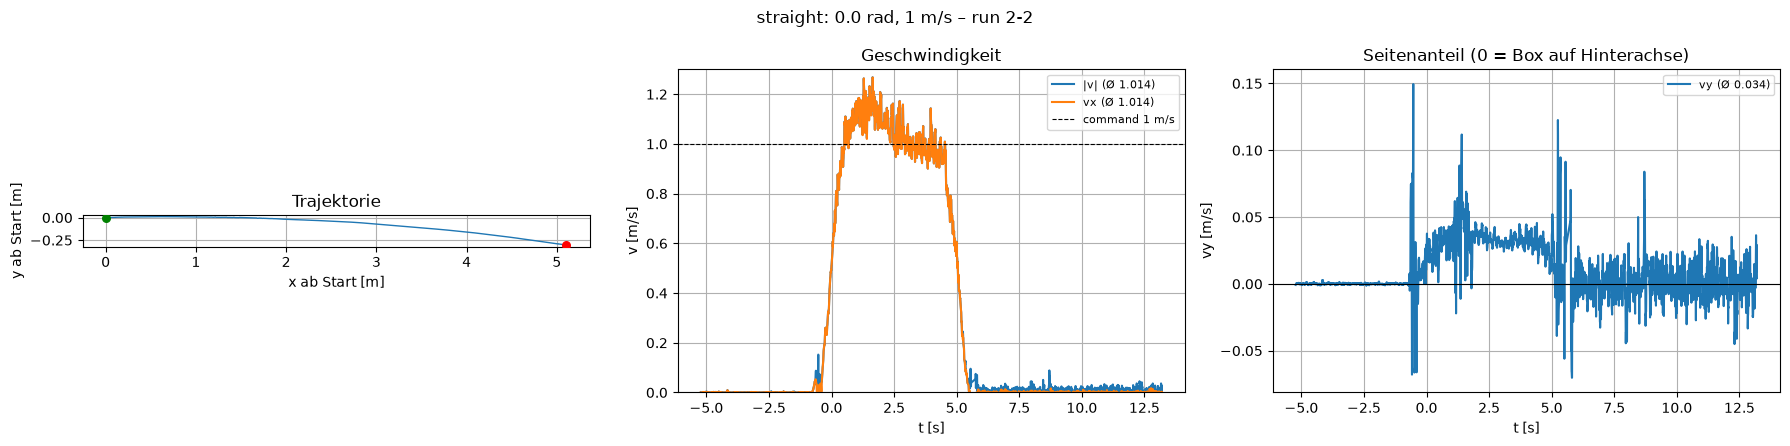

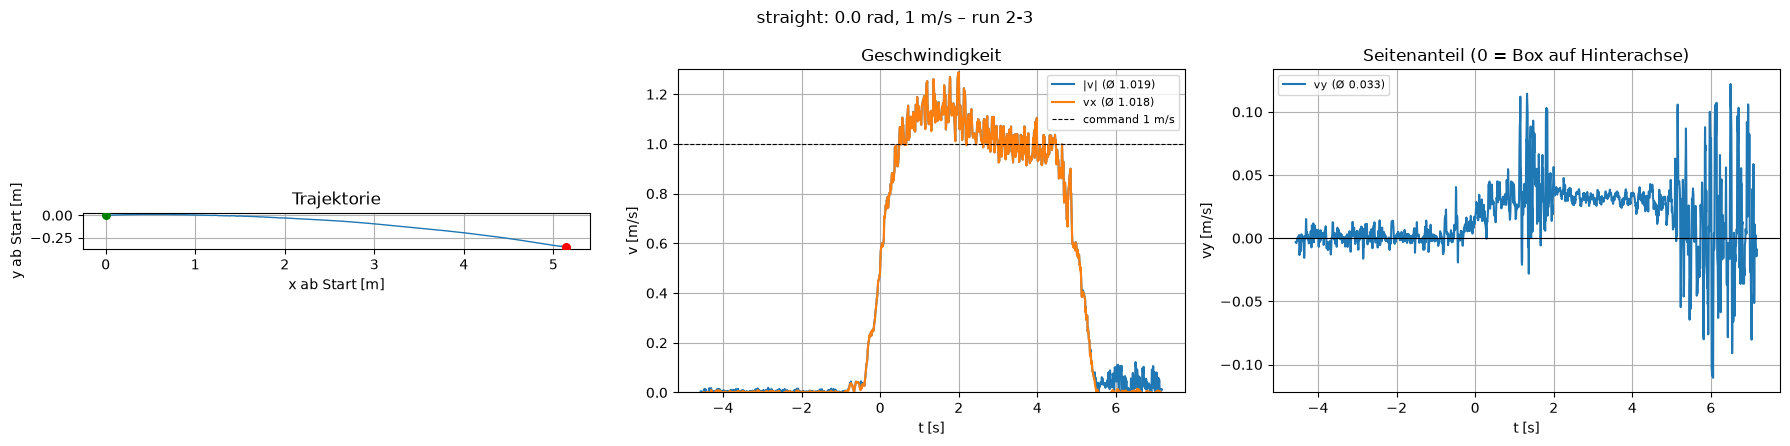

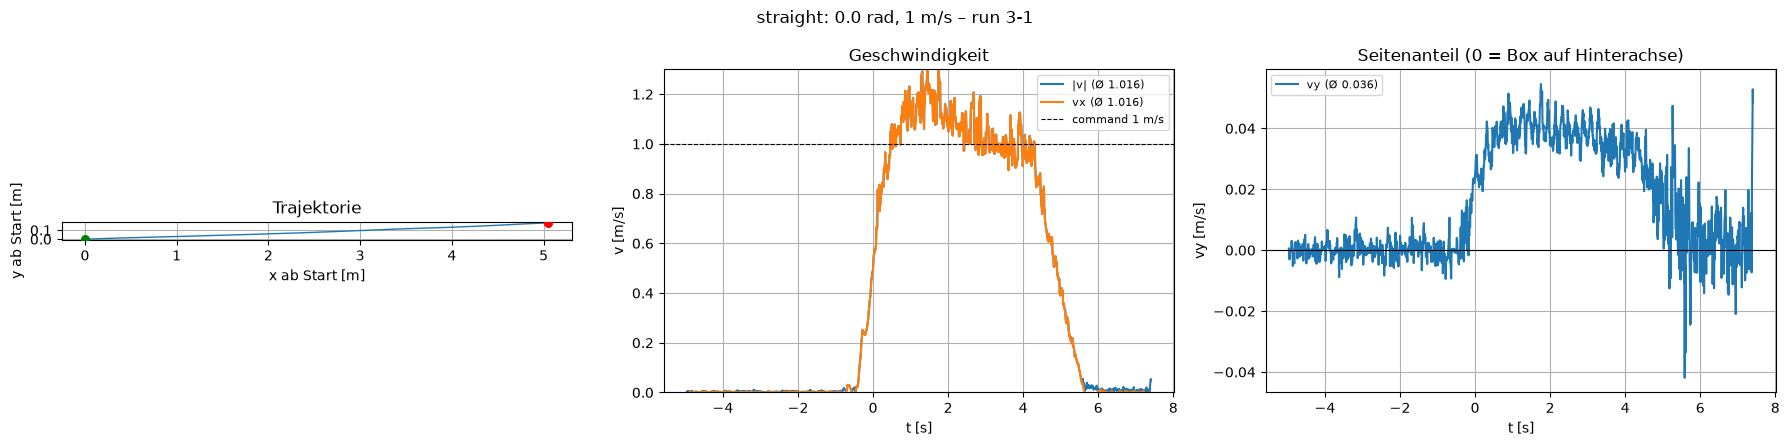

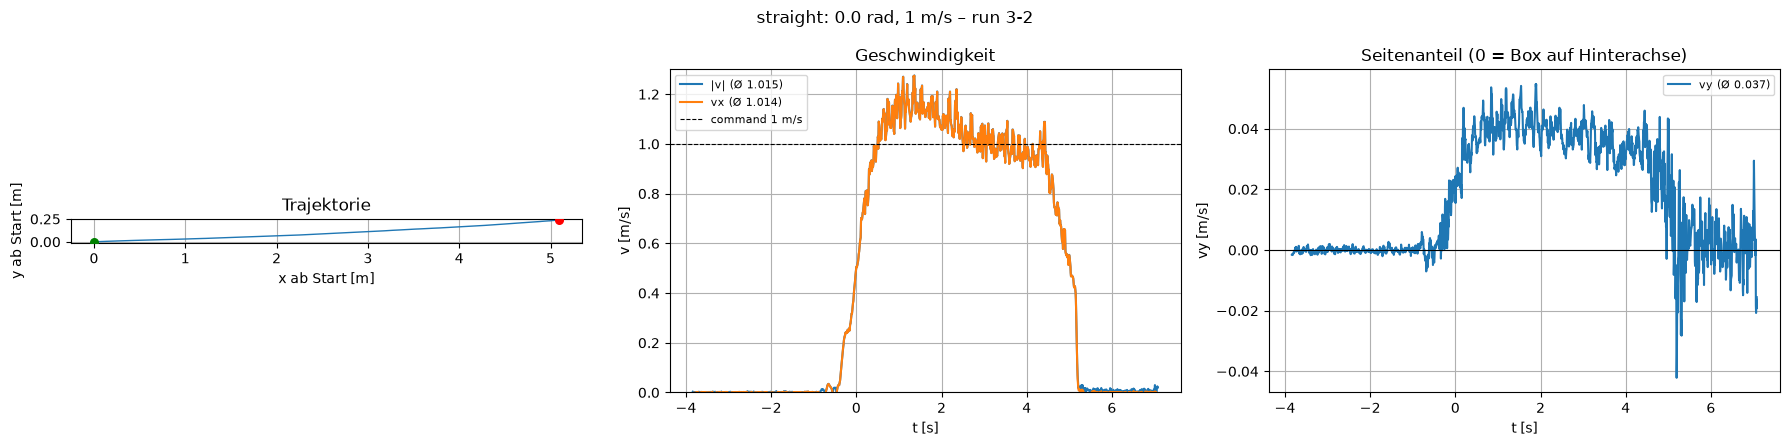

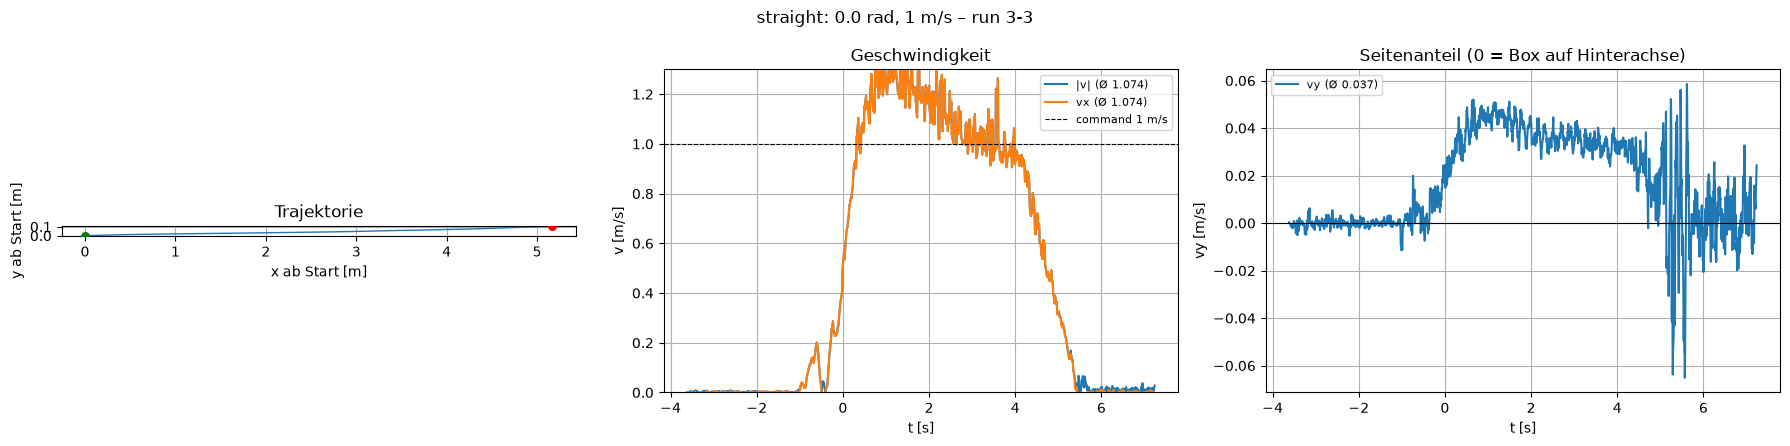

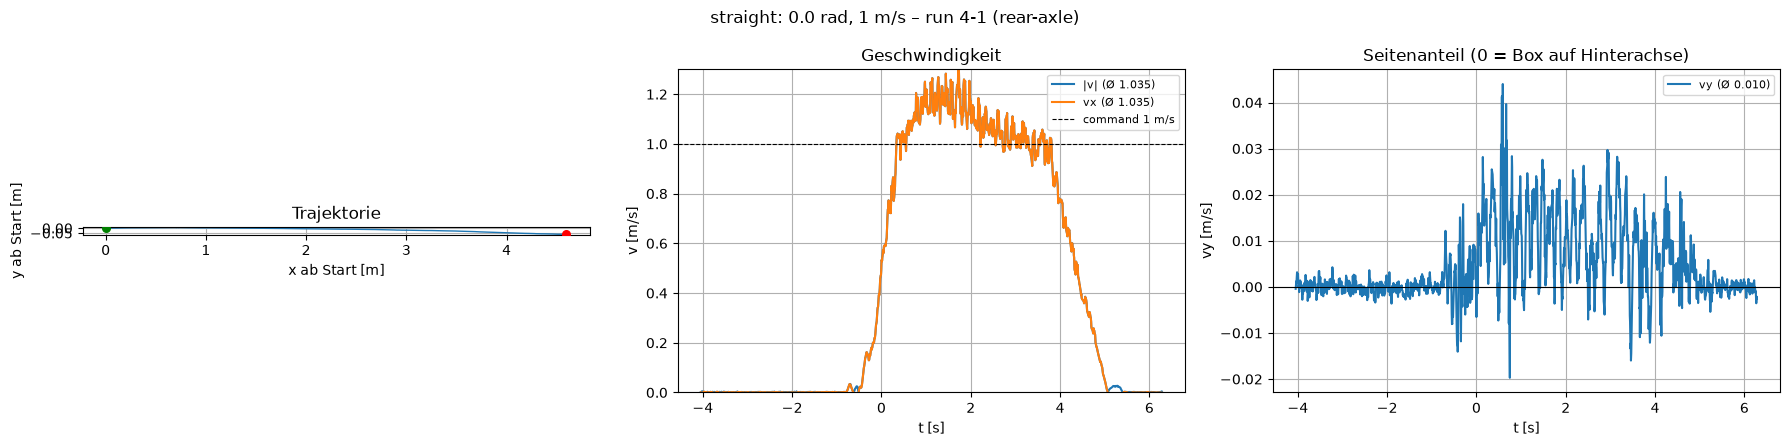

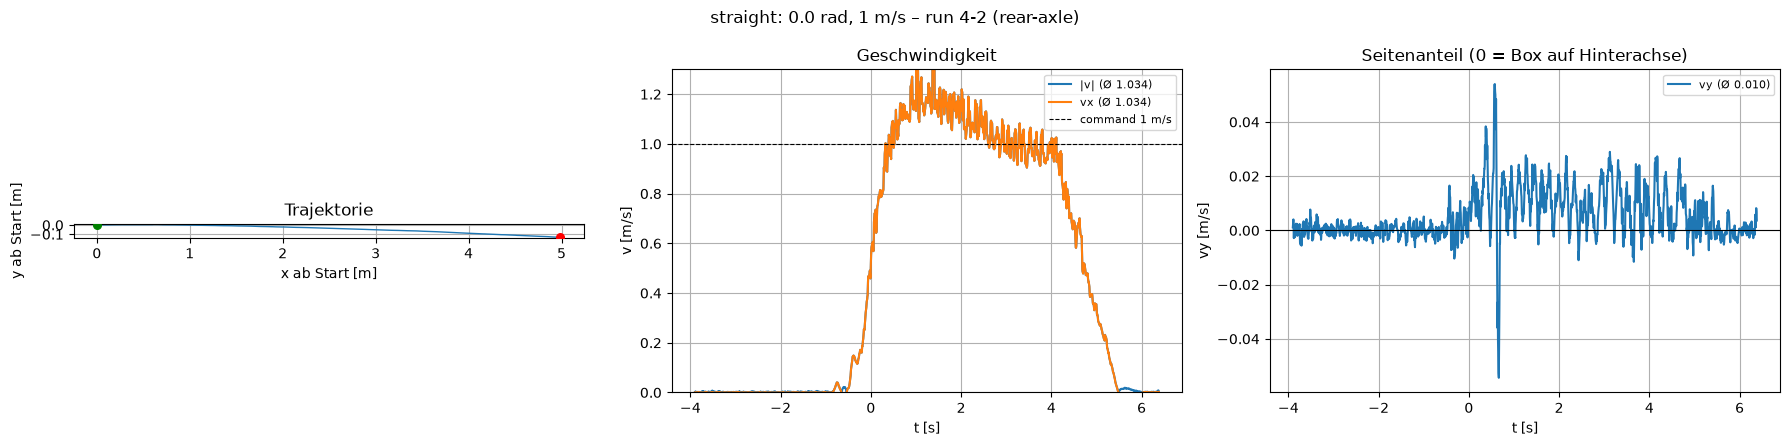

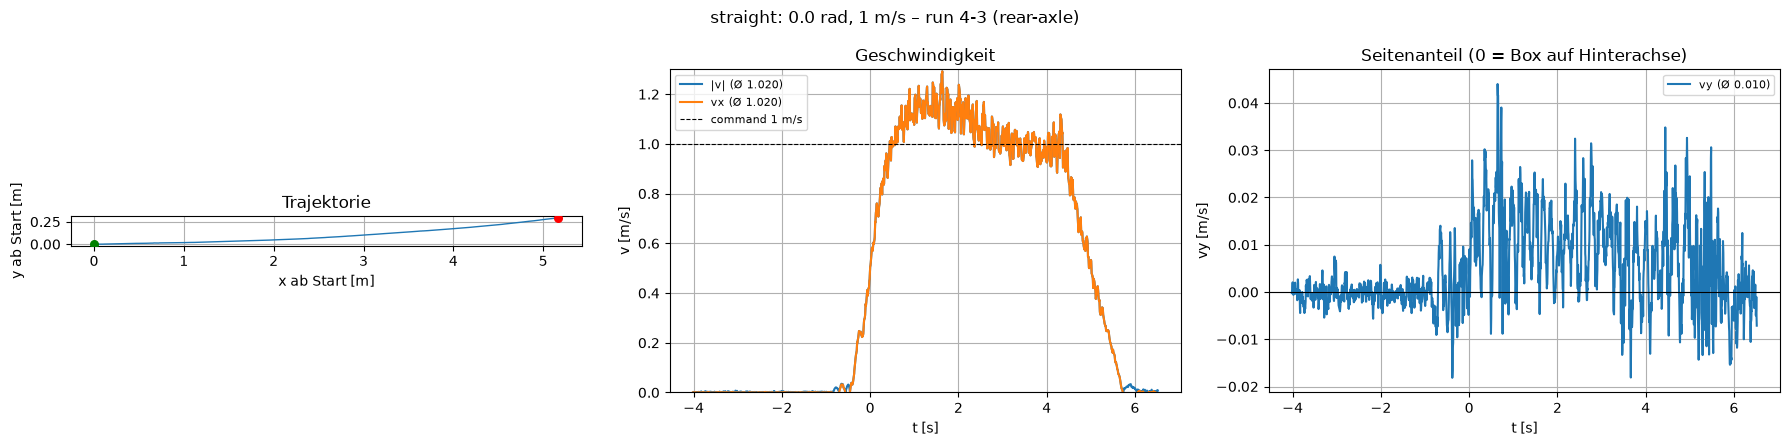

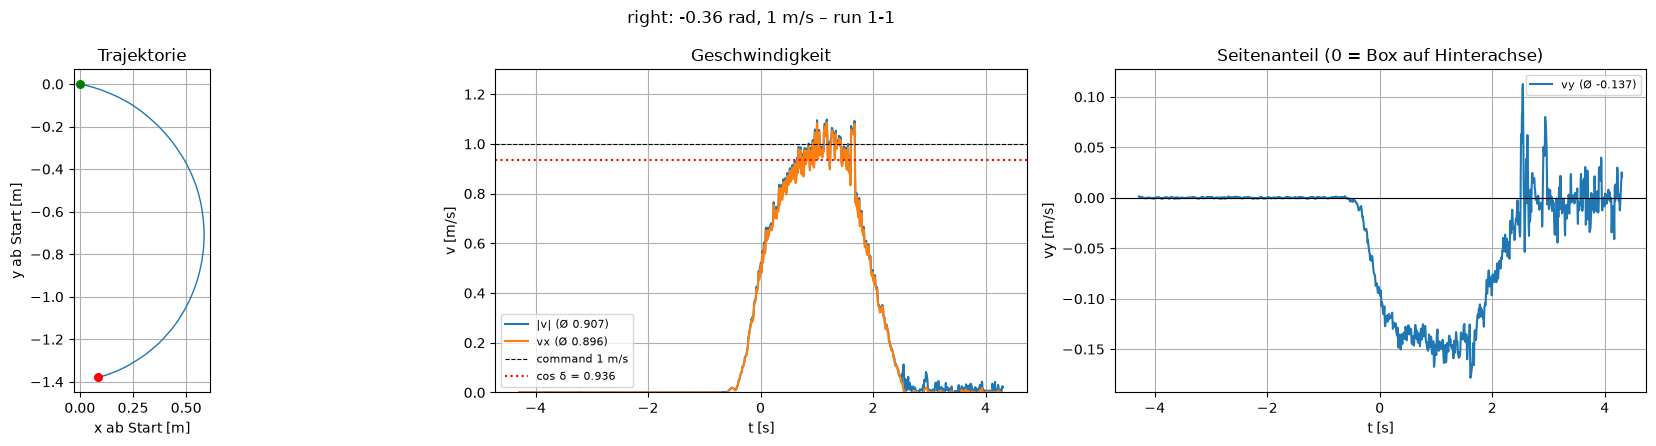

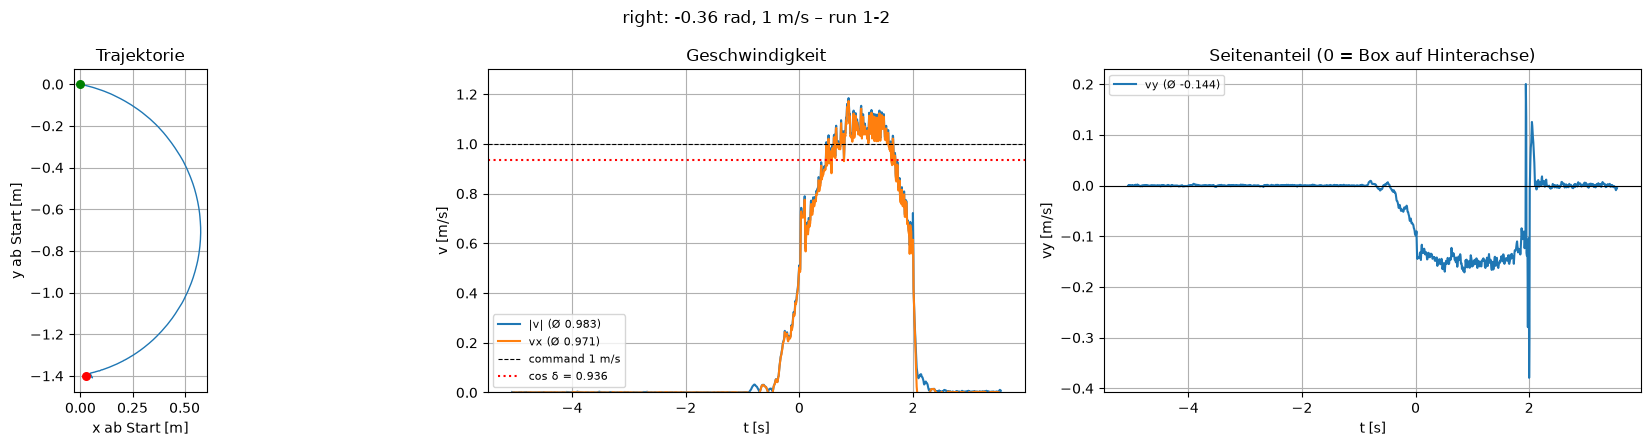

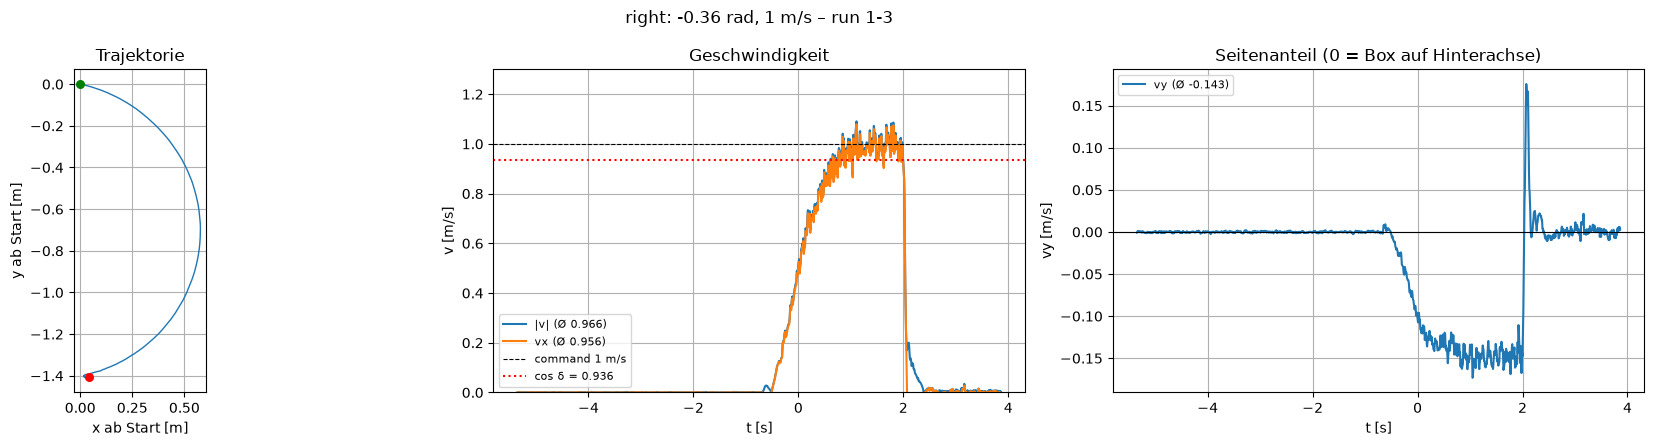

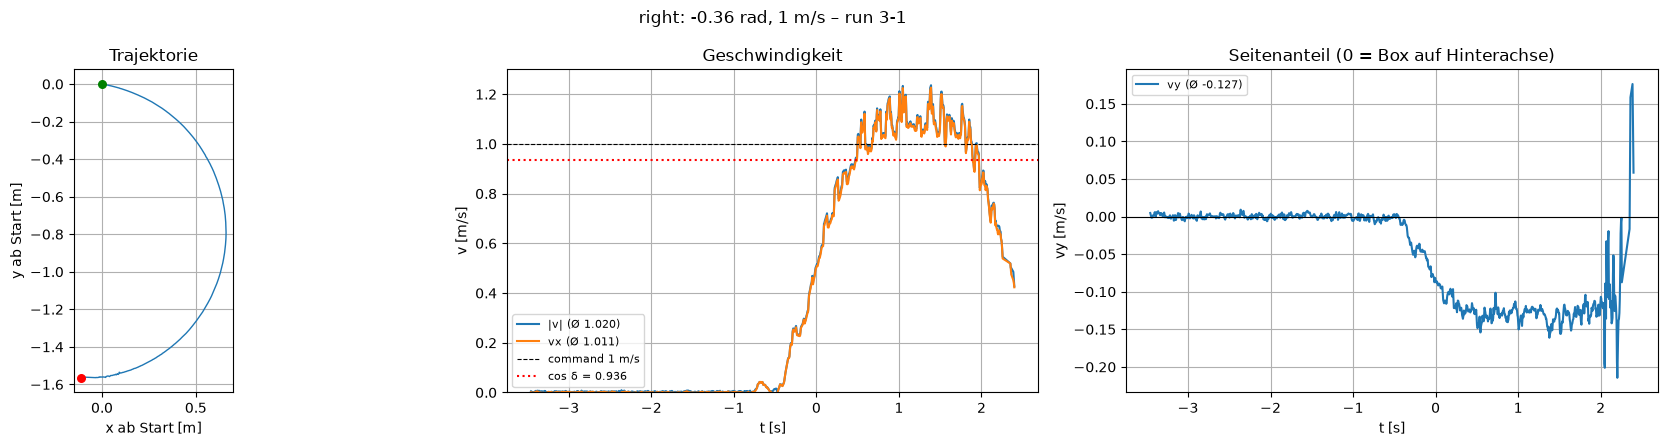

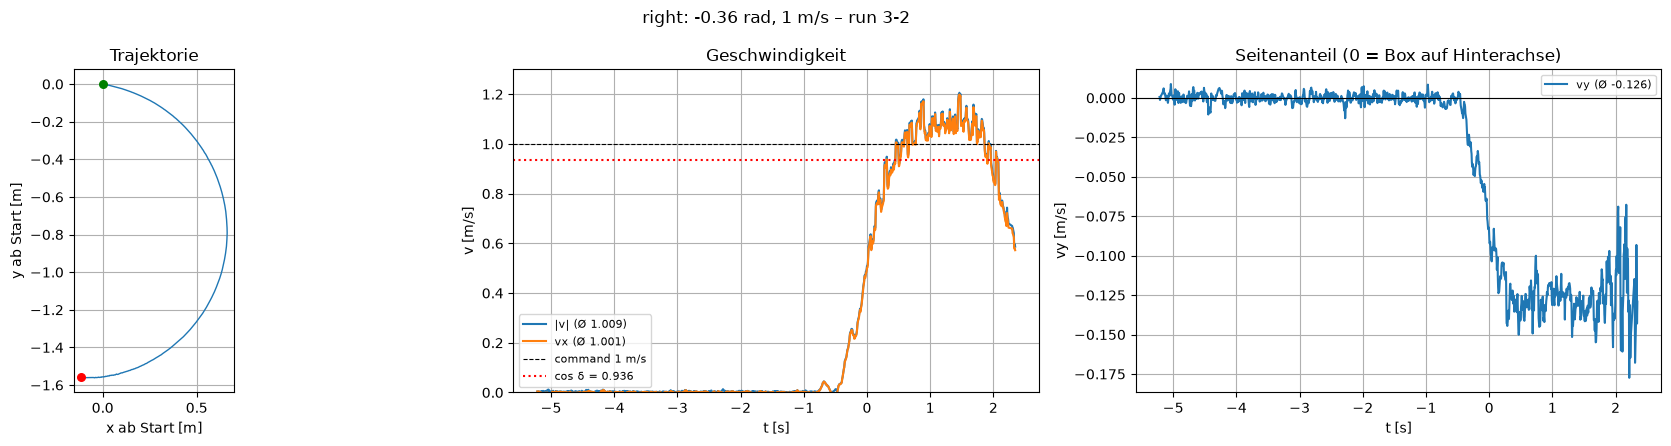

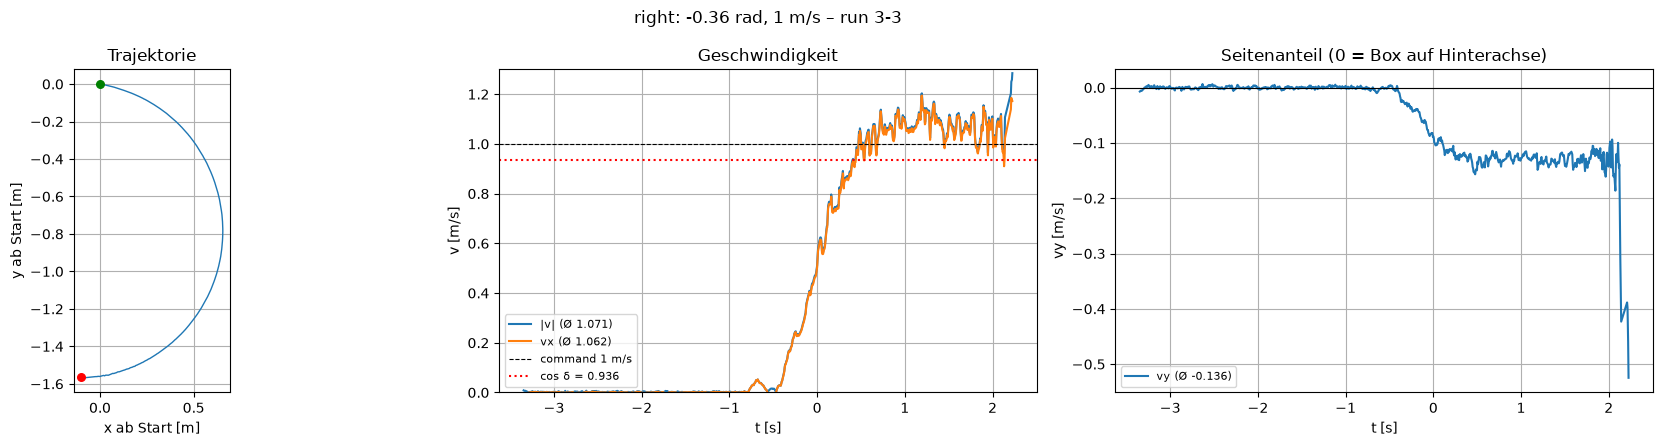

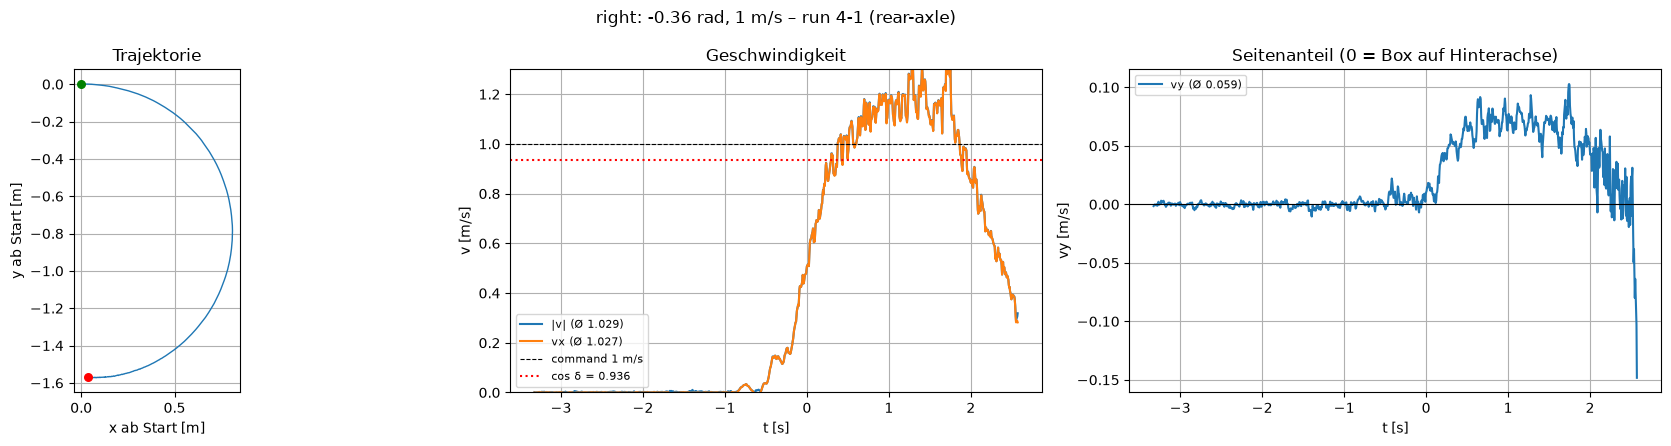

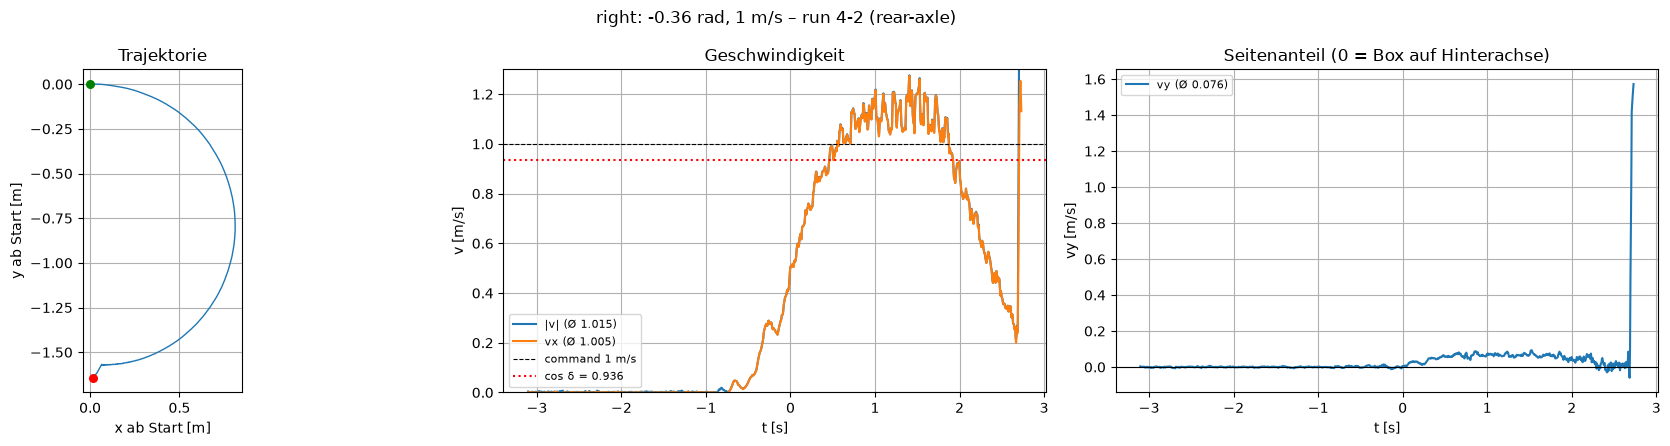

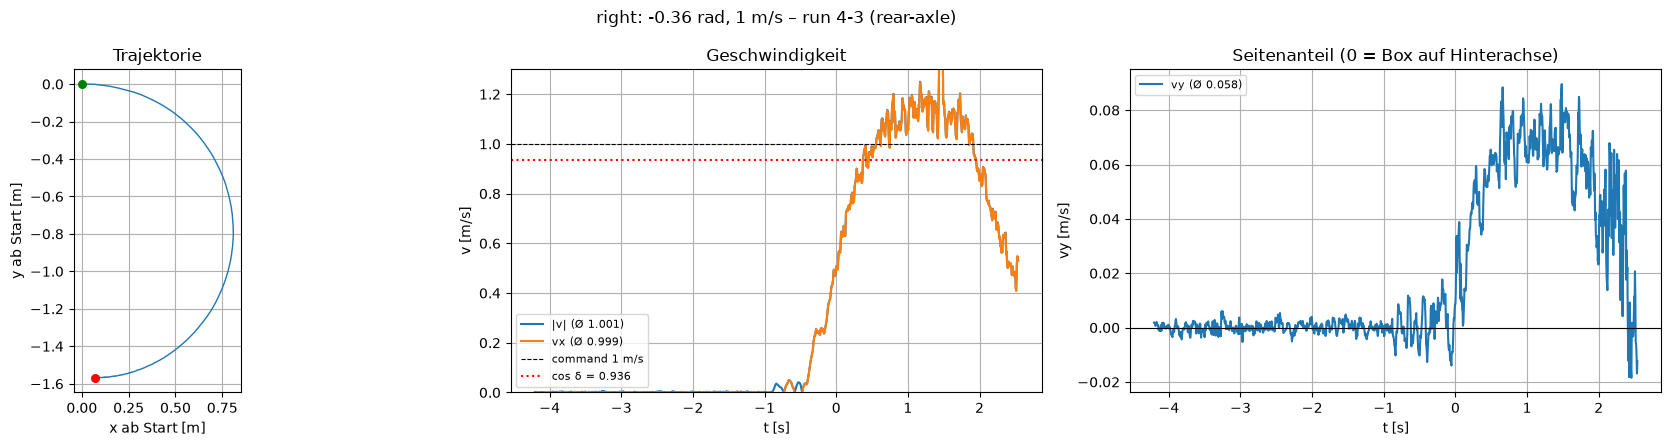

   group             run                       obj     v    vx     vy     wz  d_est  delta_eff_deg  yaw_off_deg
    left             1-1                    athena 1.119 1.099  0.206  1.418  0.129         18.541          NaN
    left             1-2                    athena 0.966 0.947  0.194  1.269  0.141         19.211          NaN
    left             1-3                    athena 1.074 1.054  0.205  1.406  0.135         19.141          NaN
    left             3-1                    athena 0.973 0.945  0.231  1.473  0.169         22.047          NaN
    left             3-2                    athena 1.055 1.026  0.246  1.634  0.166         22.492          NaN
    left             3-3                    athena 0.972 0.945  0.227  1.484  0.166         22.206          NaN
    left 4-1 (rear-axle) athena_with_wheel_tracker 0.883 0.882 -0.032  1.395 -0.025         22.352          NaN
    left 4-2 (rear-axle) athena_with_wheel_tracker 0.913 0.912 -0.036  1.432 -0.027         22.209      

In [65]:
from scipy.ndimage import uniform_filter1d

L = 0.26          # Radstand des echten Autos [m] -> anpassen!
deltas = {"left": 0.36, "straight": 0.0, "right": -0.36}
v_min, t_settle, smooth = 0.5, 0.5, 9   # Fenster in Samples


def body_velocity(df, topic):
    t = df["t"].to_numpy()
    yaw = np.unwrap(vehicle_yaw(df, topic))          # mit Yaw-Offset pro Vicon-Objekt
    vxw = uniform_filter1d(np.gradient(df["px"].to_numpy(), t), smooth)
    vyw = uniform_filter1d(np.gradient(df["py"].to_numpy(), t), smooth)
    c, s = np.cos(yaw), np.sin(yaw)
    vx = c * vxw + s * vyw               # in Fahrtrichtung
    vy = -s * vxw + c * vyw              # seitlich (links positiv)
    wz = uniform_filter1d(np.gradient(yaw, t), smooth)
    return t, vx, vy, wz


summary = []
for group in groups:
    for run in sorted(dfs[group]):
        df = dfs[group][run]
        topic = topic_of[(group, run)]
        t, vx, vy, wz = body_velocity(df, topic)

        moving = np.flatnonzero(np.abs(vx) > v_min)
        if len(moving) == 0:
            print(f"{group} {run}: nie schneller als {v_min} m/s, übersprungen")
            continue
        t0 = t[moving[0]]
        ss = (t - t0 > t_settle) & (np.abs(vx) > v_min)   # stationärer Teil
        if not ss.any():
            print(f"{group} {run}: kein stationärer Teil, übersprungen")
            continue

        vx_m, vy_m = vx[ss].mean(), vy[ss].mean()
        v_m = np.hypot(vx, vy)[ss].mean()
        wz_m = wz[ss].mean()
        d_est = L * (vy_m / vx_m) / np.tan(deltas[group]) if deltas[group] else np.nan
        d_eff = np.degrees(np.arctan(wz_m * L / vx_m)) if deltas[group] else np.nan
        yaw_off = np.degrees(np.arctan2(vy_m, vx_m)) if group == "straight" else np.nan
        summary.append(dict(group=group, run=run, obj=topic.split("/")[2],
                            v=v_m, vx=vx_m, vy=vy_m, wz=wz_m,
                            d_est=d_est, delta_eff_deg=d_eff, yaw_off_deg=yaw_off))

        fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(18, 4.5))
        fig.suptitle(f"{titles[group]} – run {run}")

        da = align_start(df, topic)
        a1.plot(da["ax"], da["ay"], lw=1)
        a1.scatter(0, 0, c="green", s=30, zorder=3)
        a1.scatter(da["ax"].iloc[-1], da["ay"].iloc[-1], c="red", s=30, zorder=3)
        a1.set_aspect("equal"); a1.grid(True)
        a1.set_xlabel("x ab Start [m]"); a1.set_ylabel("y ab Start [m]")
        a1.set_title("Trajektorie")

        a2.plot(t - t0, np.hypot(vx, vy), label=f"|v| (Ø {v_m:.3f})")
        a2.plot(t - t0, vx, label=f"vx (Ø {vx_m:.3f})")
        a2.axhline(1.0, color="k", ls="--", lw=0.8, label="command 1 m/s")
        if deltas[group]:
            a2.axhline(np.cos(deltas[group]), color="r", ls=":",
                       label=f"cos δ = {np.cos(deltas[group]):.3f}")
        a2.set_ylim(0, 1.3); a2.grid(True); a2.legend(fontsize=8)
        a2.set_xlabel("t [s]"); a2.set_ylabel("v [m/s]"); a2.set_title("Geschwindigkeit")

        a3.plot(t - t0, vy, label=f"vy (Ø {vy_m:.3f})")
        a3.axhline(0, color="k", lw=0.8)
        a3.grid(True); a3.legend(fontsize=8)
        a3.set_xlabel("t [s]"); a3.set_ylabel("vy [m/s]")
        a3.set_title("Seitenanteil (0 = Box auf Hinterachse)")

        plt.tight_layout(); plt.show()

print(pd.DataFrame(summary).round(3).to_string(index=False))

##### Check on real Speed

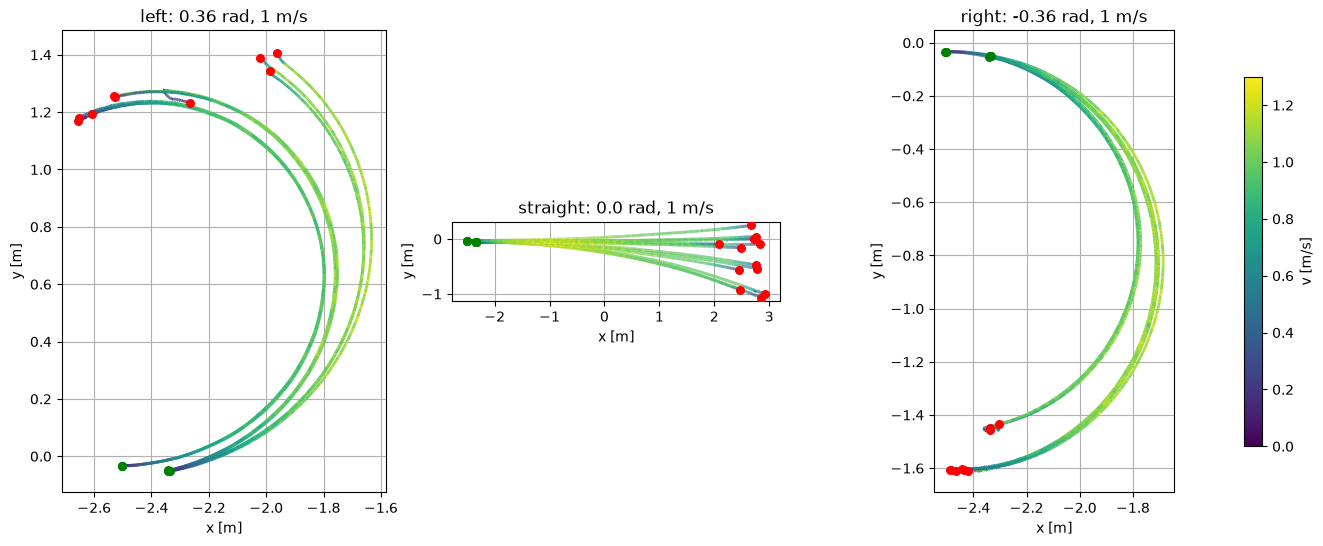

In [66]:
from matplotlib.collections import LineCollection

k = 5
vmax_plot = 1.3  # obere Grenze der Farbskala [m/s]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    for run in sorted(dfs[g]):
        df = dfs[g][run].drop_duplicates(subset="t")
        t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
        v = np.hypot(x[2*k:] - x[:-2*k], y[2*k:] - y[:-2*k]) / (t[2*k:] - t[:-2*k])
        xm, ym = x[k:-k], y[k:-k]  # Positionen passend zu v

        segs = np.stack([np.column_stack([xm[:-1], ym[:-1]]),
                         np.column_stack([xm[1:], ym[1:]])], axis=1)
        lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, vmax_plot), linewidth=2)
        lc.set_array(v[:-1])
        ax.add_collection(lc)
        ax.scatter(xm[0], ym[0], color="green", s=30, zorder=3)
        ax.scatter(xm[-1], ym[-1], color="red", s=30, zorder=3)

    ax.autoscale()
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_aspect("equal"); ax.grid(True)

fig.colorbar(lc, ax=axes, label="v [m/s]", shrink=0.8)
plt.show()

Steady-state mean speed [m/s] per point (same run, same time base):
   group             run  chassis  rear axle  front axle  front/rear  rear slip [deg]
    left             1-1    1.112      1.101       1.164       1.057           -3.549
    left             1-2    0.988      0.975       1.041       1.068           -2.980
    left             1-3    1.082      1.069       1.137       1.064           -3.220
    left             3-1    0.970      0.953       1.037       1.088           -3.612
    left             3-2    1.037      1.018       1.110       1.091           -3.649
    left             3-3    1.019      1.001       1.090       1.089           -3.785
    left 4-1 (rear-axle)    0.941      0.918       1.015       1.105           -2.793
    left 4-2 (rear-axle)    0.956      0.932       1.031       1.105           -2.722
    left 4-3 (rear-axle)    0.949      0.922       1.026       1.112           -2.040
straight             1-1    1.043      1.043       1.043       1.000    

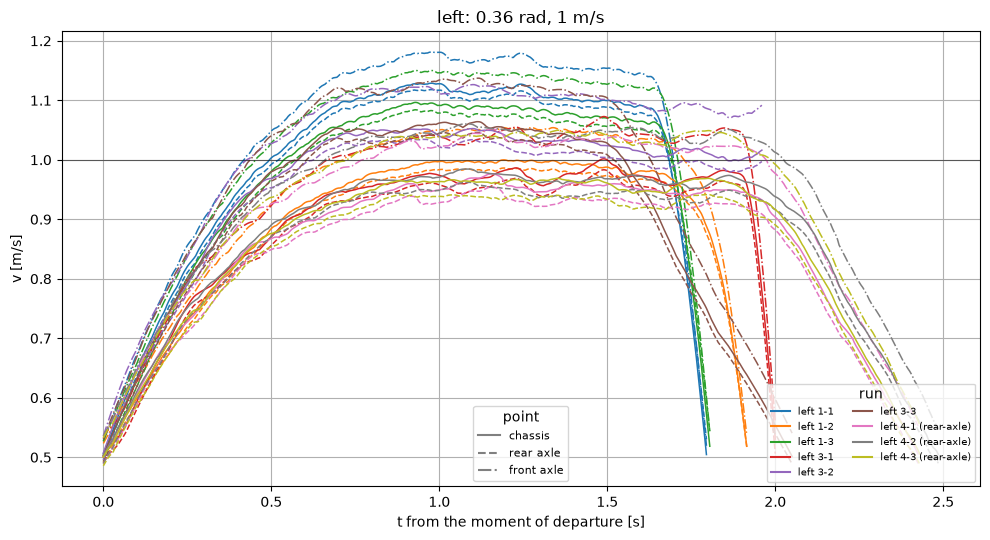

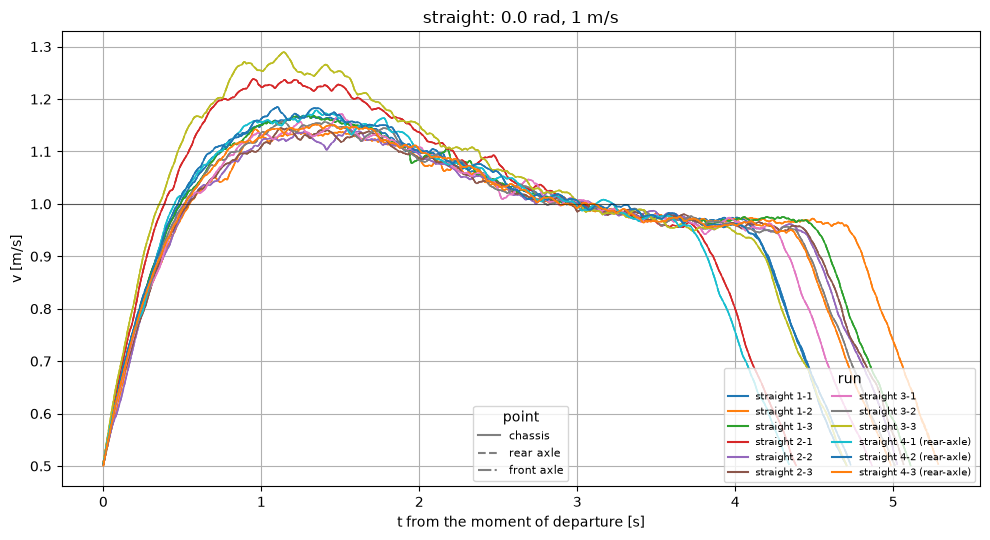

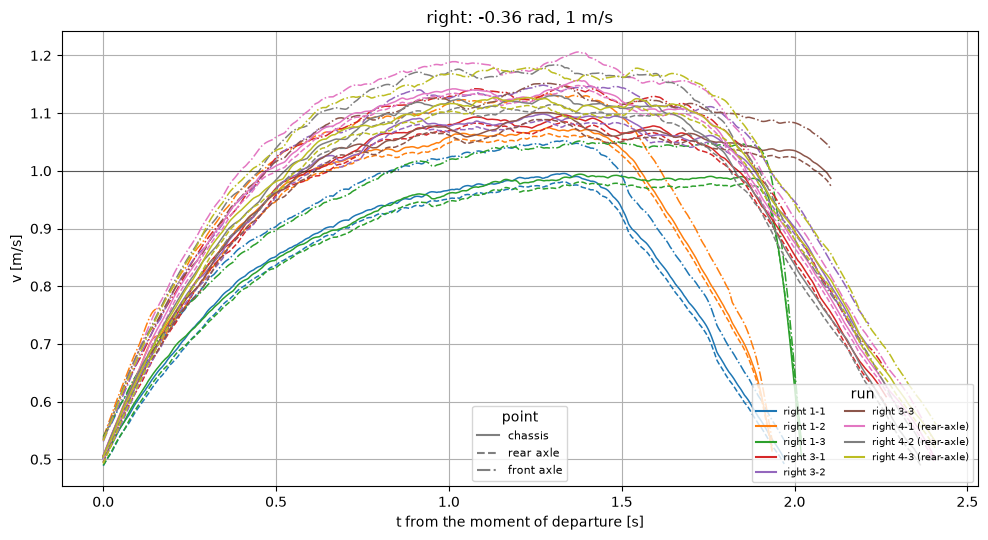

In [67]:
# Notebook cell: run after the cell that builds `dfs`, `groups`, `titles`
# (dfs[group][run] = DataFrame with t, px, py, qx, qy, qz, qw)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import savgol_filter

rate = 200          # resampling rate [Hz]
win_s = 0.25         # Savitzky-Golay window length [s]
v_min = 0.5         # below this speed (start/end) the car counts as standing still
STEADY_FROM = 0.7   # steady part starts this long after departure [s]
STEADY_END = 0.3    # ... and ends this long before the end [s]
NORMALIZED = True   # True if dfs went through normalize_start() (positions rotated, quaternions not)

# Position of each point along the car's longitudinal axis, relative to the
# chassis centre [m], forward = positive. Leatherback values from the Isaac Sim
# docs - measure them on your real car!
POINTS = {"chassis": 0.0, "rear axle": -0.17, "front axle": 0.15}
STYLES = {"chassis": "-", "rear axle": "--", "front axle": "-."}
colors = plt.cm.tab10.colors


def tracked_x(run):
    """Where px/py sits on the car: series 4 was shifted to the rear axle,
    all other series sit at the chassis centre."""
    return POINTS["rear axle"] if str(run).startswith("4") else POINTS["chassis"]


def heading(df):
    """Yaw angle from the quaternion, unwrapped so it can be interpolated."""
    qx, qy, qz, qw = (df[c].to_numpy() for c in ["qx", "qy", "qz", "qw"])
    yaw = np.unwrap(np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy ** 2 + qz ** 2)))
    if NORMALIZED:
        # normalize_start() rotated the positions by -yaw0 but not the quaternions
        yaw = yaw - yaw[0]
    return yaw


def analyse_run(df):
    """Speed of every point in POINTS, all on the same time base.
    Returns (time since departure, {point: speed}, {point: velocity angle - yaw})."""
    df = df.drop_duplicates(subset="t")
    t, x, y, yaw = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy(), heading(df)

    # resample everything onto a regular grid
    tm = np.arange(t[0], t[-1], 1 / rate)
    xu, yu, yawu = (np.interp(tm, t, s) for s in (x, y, yaw))

    win = int(win_s * rate) | 1          # odd window length for savgol_filter
    h = win // 2
    x0 = tracked_x(run)

    speeds, slip = {}, {}
    for name, xp in POINTS.items():
        # shift the tracked point along the car's heading to this point
        dx = xp - x0
        px = xu + np.cos(yawu) * dx
        py = yu + np.sin(yawu) * dx
        vx = savgol_filter(px, win, polyorder=2, deriv=1, delta=1 / rate)
        vy = savgol_filter(py, win, polyorder=2, deriv=1, delta=1 / rate)
        speeds[name] = np.hypot(vx, vy)[h:-h]
        # angle between direction of travel and heading (should be ~0 at the rear axle)
        slip[name] = np.angle(np.exp(1j * (np.arctan2(vy, vx) - yawu)))[h:-h]
    tm = tm[h:-h]

    # cut standstill at start/end, using the chassis speed for all points
    idx = np.flatnonzero(speeds["chassis"] > v_min)
    if idx.size == 0:
        return None
    sl = slice(idx[0], idx[-1] + 1)
    tm = tm[sl] - tm[sl][0]
    return tm, {k: v[sl] for k, v in speeds.items()}, {k: s[sl] for k, s in slip.items()}


# ---------------------------------------------------------------------------
# One figure per direction: colour = run, line style = point on the car
# ---------------------------------------------------------------------------
summary = []
for g in groups:
    if not dfs[g]:
        continue
    fig, ax = plt.subplots(figsize=(10, 5.5))
    run_handles = []
    for i, run in enumerate(sorted(dfs[g])):
        res = analyse_run(dfs[g][run])
        if res is None:
            print(f"{g} {run}: never faster than {v_min} m/s, skipped")
            continue
        tm, speeds, slip = res
        c = colors[i % len(colors)]
        steady = (tm > STEADY_FROM) & (tm < tm[-1] - STEADY_END)

        row = {"group": g, "run": run}
        for name, v in speeds.items():
            ax.plot(tm, v, linestyle=STYLES[name], color=c, lw=1.1)
            row[name] = v[steady].mean() if steady.any() else np.nan
        row["front/rear"] = row["front axle"] / row["rear axle"]
        row["rear slip [deg]"] = (np.degrees(slip["rear axle"][steady].mean())
                                  if steady.any() else np.nan)
        summary.append(row)
        run_handles.append(Line2D([], [], color=c, label=f"{g} {run}"))

    ax.axhline(1.0, color="k", lw=0.8, alpha=0.5)

    # two legends: colours = runs, line styles = points
    style_handles = [Line2D([], [], color="gray", linestyle=s, label=n) for n, s in STYLES.items()]
    leg = ax.legend(handles=run_handles, loc="lower right", fontsize=7, title="run", ncol=2)
    ax.add_artist(leg)
    ax.legend(handles=style_handles, loc="lower center", fontsize=8, title="point")

    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.set_ylabel("v [m/s]")
    ax.grid(True)
    fig.tight_layout()

summary = pd.DataFrame(summary)
print("Steady-state mean speed [m/s] per point (same run, same time base):")
print(summary.round(3).to_string(index=False))
plt.show()

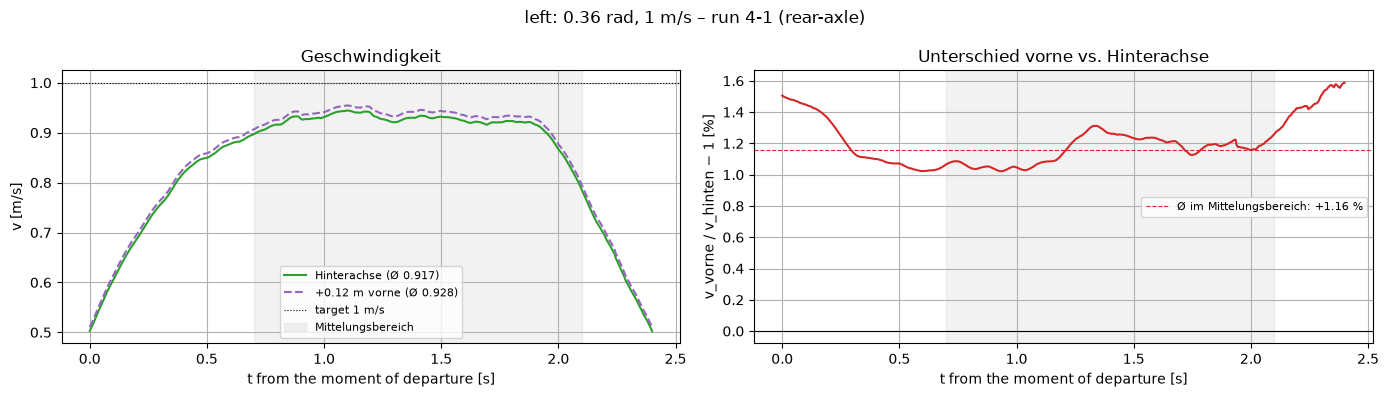

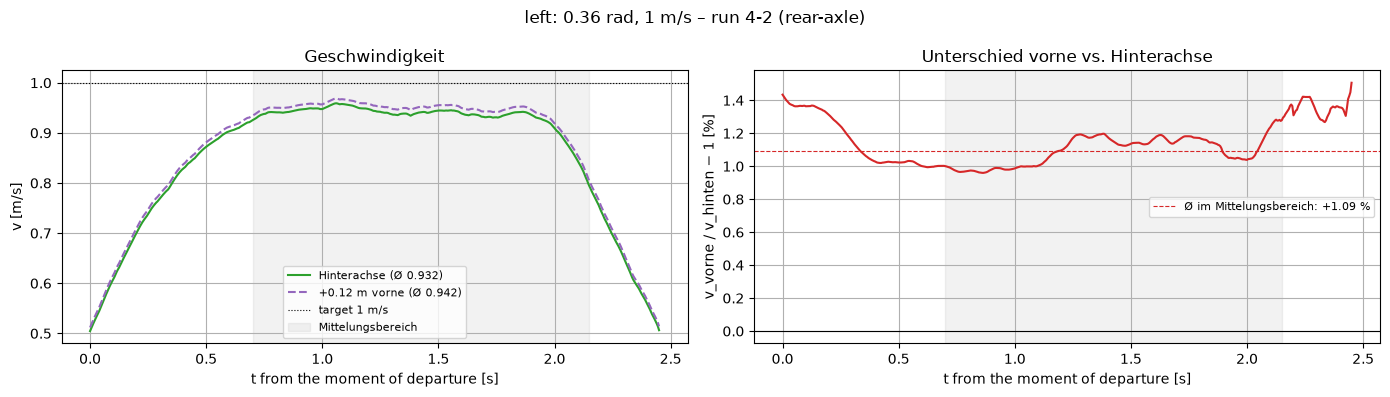

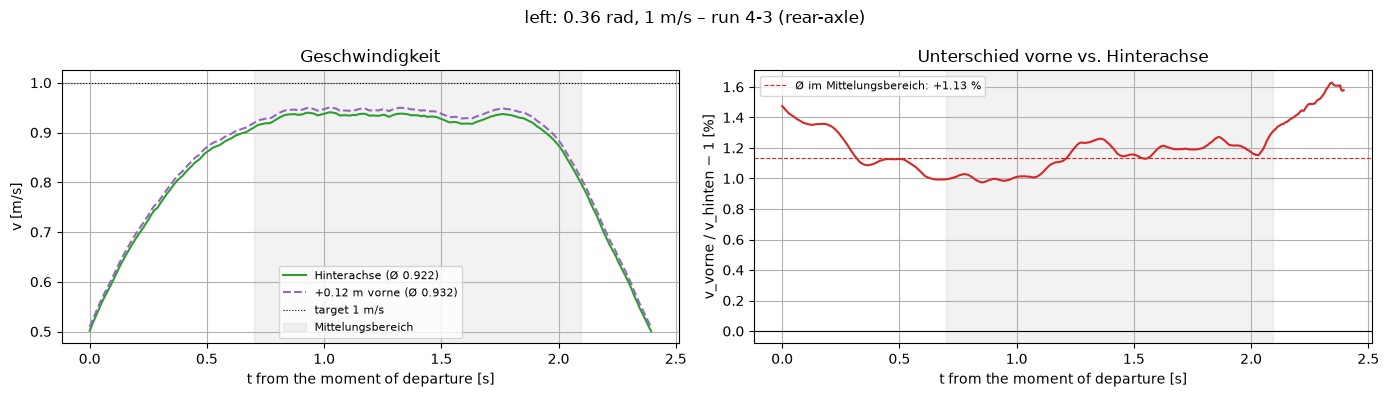

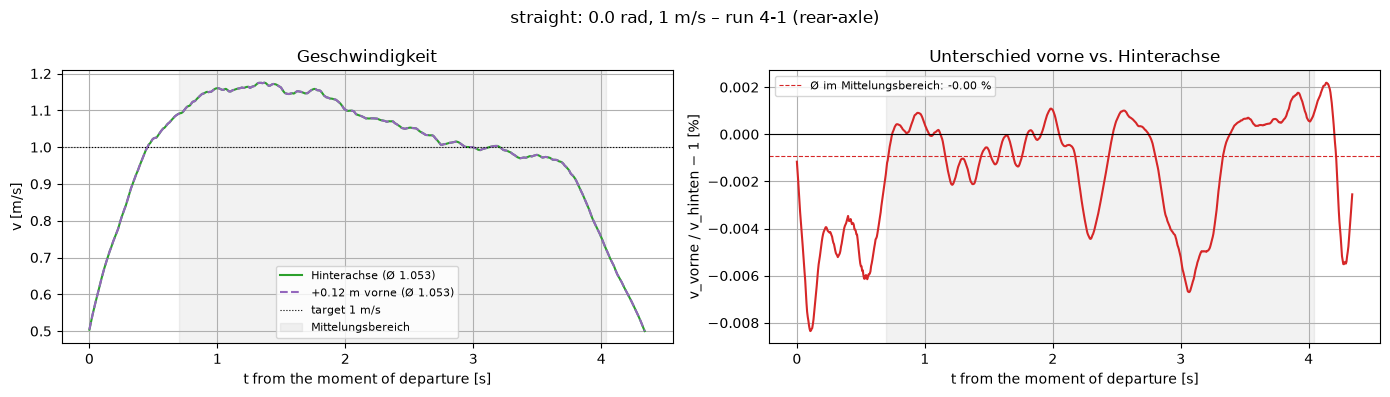

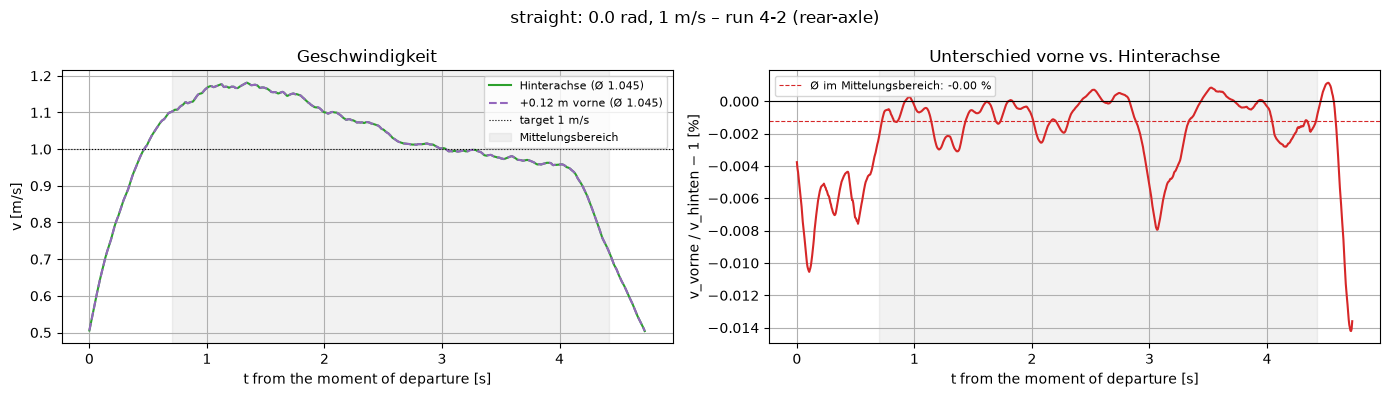

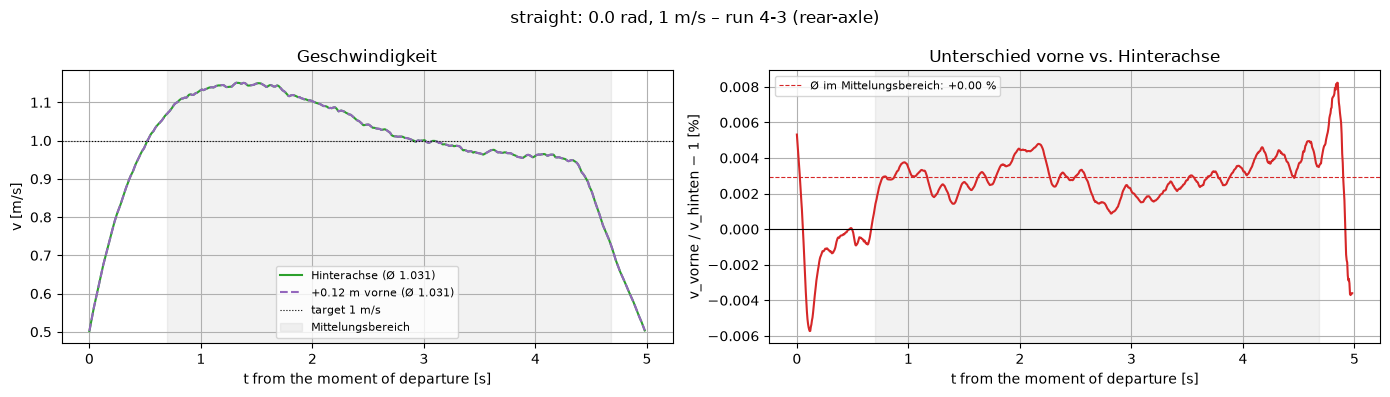

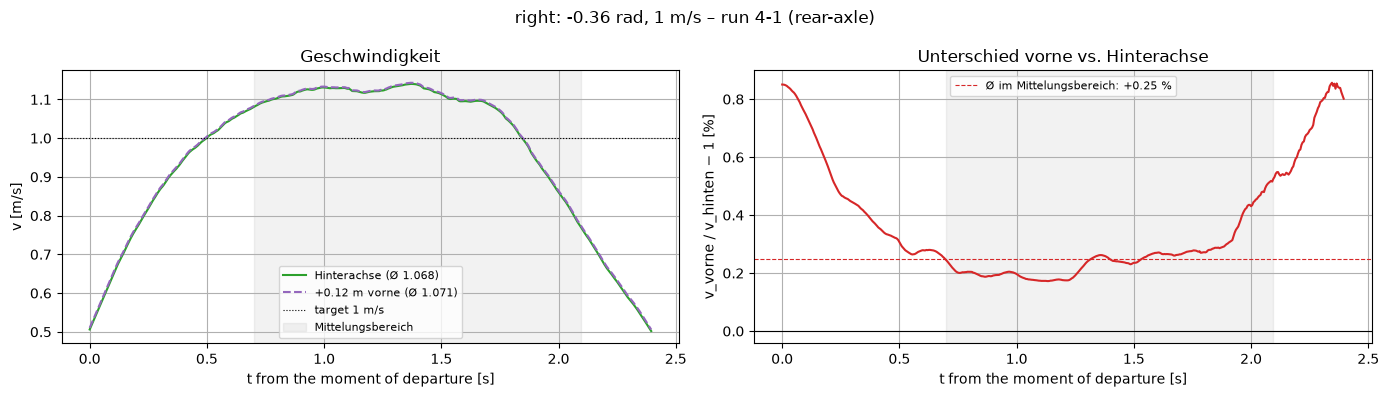

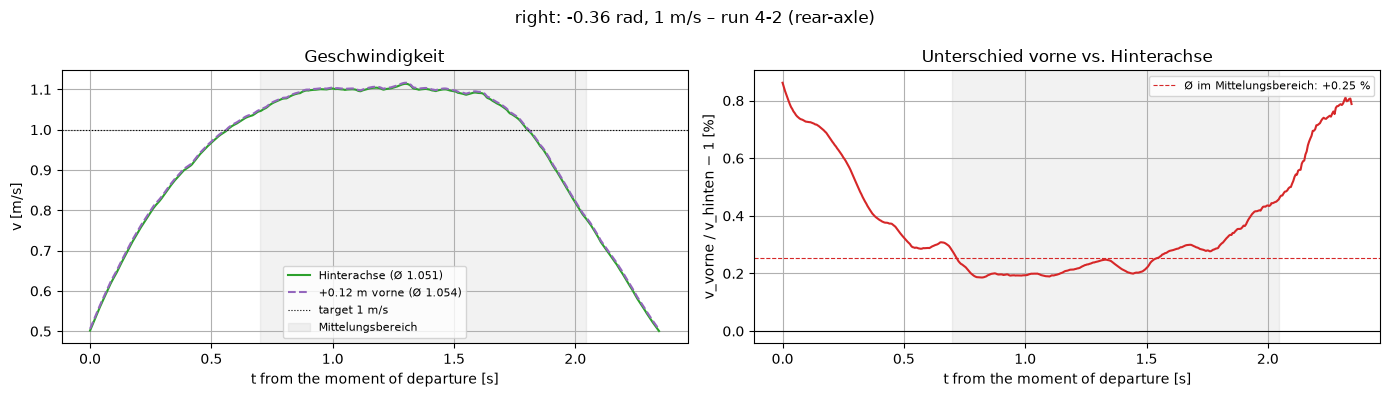

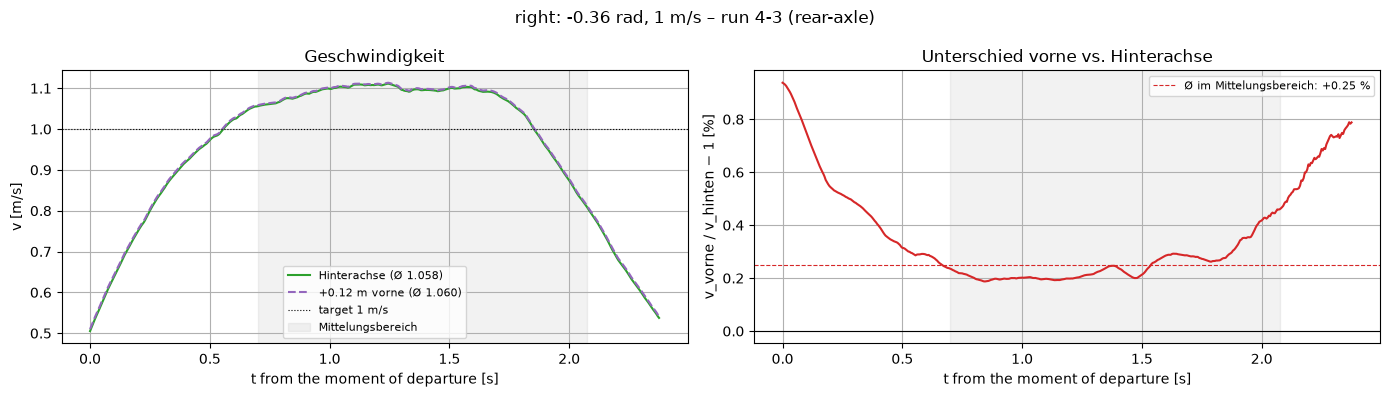

   group             run  v_rear  v_front  diff_pct
    left 4-1 (rear-axle)   0.917    0.928     1.158
    left 4-2 (rear-axle)   0.932    0.942     1.094
    left 4-3 (rear-axle)   0.922    0.932     1.134
straight 4-1 (rear-axle)   1.053    1.053    -0.001
straight 4-2 (rear-axle)   1.045    1.045    -0.001
straight 4-3 (rear-axle)   1.031    1.031     0.003
   right 4-1 (rear-axle)   1.068    1.071     0.249
   right 4-2 (rear-axle)   1.051    1.054     0.252
   right 4-3 (rear-axle)   1.058    1.060     0.248


In [68]:
from scipy.signal import savgol_filter

rate = 200        # Raster in Hz
win_s = 0.3       # Fensterlänge in Sekunden
v_min = 0.5
d_front = 0.12    # virtueller Punkt vor der Hinterachse [m] (≈ alte Box)


def speed(df, topic, d=0.0):
    """|v| eines Punkts d Meter vor dem Vicon-Ursprung, in Fahrzeugrichtung."""
    df = df.drop_duplicates(subset="t")
    t = df["t"].to_numpy()
    yaw = np.unwrap(vehicle_yaw(df, topic))
    x = df["px"].to_numpy() + d * np.cos(yaw)
    y = df["py"].to_numpy() + d * np.sin(yaw)

    tm = np.arange(t[0], t[-1], 1 / rate)
    xu, yu = np.interp(tm, t, x), np.interp(tm, t, y)

    win = int(win_s * rate) | 1          # ungerade Fensterlänge für savgol
    vx = savgol_filter(xu, win, polyorder=2, deriv=1, delta=1 / rate)
    vy = savgol_filter(yu, win, polyorder=2, deriv=1, delta=1 / rate)
    v = np.hypot(vx, vy)

    h = win // 2
    return tm[h:-h], v[h:-h]


rows = []
for g in groups:
    for run in sorted(dfs[g]):
        if "rear-axle" not in run:
            continue                       # nur Läufe mit Box auf der Hinterachse
        topic = topic_of[(g, run)]

        tm, v0 = speed(dfs[g][run], topic, d=0.0)
        _, vd = speed(dfs[g][run], topic, d=d_front)   # gleiches Zeitraster

        idx = np.flatnonzero(v0 > v_min)
        if len(idx) == 0:
            print(f"{g} {run}: nie schneller als {v_min} m/s, übersprungen")
            continue
        sl = slice(idx[0], idx[-1] + 1)
        tm, v0, vd = tm[sl] - tm[idx[0]], v0[sl], vd[sl]

        steady = (tm > 0.7) & (tm < tm[-1] - 0.3)
        if not steady.any():
            print(f"{g} {run}: kein stationärer Teil, übersprungen")
            continue
        m0, md = v0[steady].mean(), vd[steady].mean()
        diff = 100 * (vd / v0 - 1)
        diff_m = 100 * (md / m0 - 1)
        rows.append(dict(group=g, run=run, v_rear=m0, v_front=md, diff_pct=diff_m))

        fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
        fig.suptitle(f"{titles[g]} – run {run}")

        a1.plot(tm, v0, color="tab:green", label=f"Hinterachse (Ø {m0:.3f})")
        a1.plot(tm, vd, color="tab:purple", ls="--",
                label=f"+{d_front:.2f} m vorne (Ø {md:.3f})")
        a1.axhline(1.0, color="k", ls=":", lw=0.8, label="target 1 m/s")
        a1.axvspan(tm[steady][0], tm[steady][-1], color="gray", alpha=0.1,
                   label="Mittelungsbereich")
        a1.set_xlabel("t from the moment of departure [s]")
        a1.set_ylabel("v [m/s]")
        a1.set_title("Geschwindigkeit")
        a1.grid(True); a1.legend(fontsize=8)

        a2.plot(tm, diff, color="tab:red")
        a2.axhline(diff_m, color="tab:red", ls="--", lw=0.8,
                   label=f"Ø im Mittelungsbereich: {diff_m:+.2f} %")
        a2.axhline(0, color="k", lw=0.8)
        a2.axvspan(tm[steady][0], tm[steady][-1], color="gray", alpha=0.1)
        a2.set_xlabel("t from the moment of departure [s]")
        a2.set_ylabel("v_vorne / v_hinten − 1 [%]")
        a2.set_title("Unterschied vorne vs. Hinterachse")
        a2.grid(True); a2.legend(fontsize=8)

        plt.tight_layout()
        plt.show()

print(pd.DataFrame(rows).round(3).to_string(index=False))


t (header.stamp): Rate 175.2 Hz | min 3.84  max 26.55  std 1.39 ms
t_log (Aufnahme): Rate 174.9 Hz | min 3.86  max 26.49  std 1.39 ms
Korrelation dt vs dt_log: 0.9978525588468197


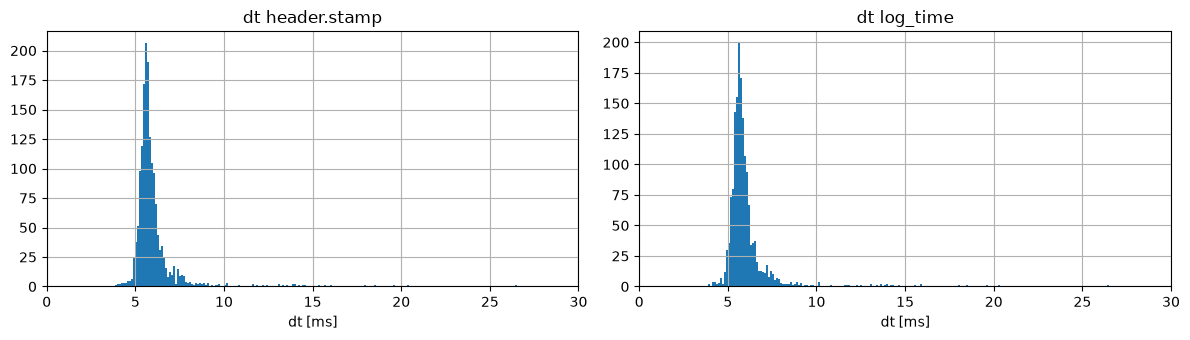

In [69]:
df = dfs["straight"]["1-1"]
dt     = np.diff(df["t"].to_numpy()) * 1e3
dt_log = np.diff(df["t_log"].to_numpy()) * 1e3

for name, d in [("t (header.stamp)", dt), ("t_log (Aufnahme)", dt_log)]:
    print(f"{name}: Rate {1e3/np.median(d):.1f} Hz | "
          f"min {d.min():.2f}  max {d.max():.2f}  std {d.std():.2f} ms")

print("Korrelation dt vs dt_log:", np.corrcoef(dt, dt_log)[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
axes[0].hist(dt, bins=200);     axes[0].set_title("dt header.stamp")
axes[1].hist(dt_log, bins=200); axes[1].set_title("dt log_time")
for ax in axes:
    ax.set_xlabel("dt [ms]"); ax.set_xlim(0, 30); ax.grid(True)
plt.tight_layout(); plt.show()

In [70]:
print((df["t_log"] - df["t"]).describe())

count    1632.000000
mean        0.000185
std         0.000063
min         0.000103
25%         0.000148
50%         0.000165
75%         0.000201
max         0.000787
dtype: float64


### Check on Simulation Datapoints

In [71]:
with open("data-sim/stage-1-test-left-1-1/stage-1-test-left-1-1.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   24
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/move_base_simple/goal                   geometry_msgs/msg/PoseStamped            0
/clicked_point                           geometry_msgs/msg/PointStamped           0
/initialpose                             geometry_msgs/msg/PoseWithCovarianceStamped 0
/tf                                      tf2_msgs/msg/TFMessage                   65
/odom                                    nav_msgs/msg/Odometry                    65
/topic                                   std_msgs/msg/Float32                     65
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 104


stage-1-test-left-1-1: 65 Msg
stage-1-test-left-1-2: 41 Msg
stage-1-test-left-1-3: 127 Msg
stage-1-test-left-2-1: 35 Msg
stage-1-test-left-2-2: 51 Msg
stage-1-test-left-2-3: 29 Msg
stage-1-test-right-1-1: 74 Msg
stage-1-test-right-1-2: 45 Msg
stage-1-test-right-1-3: 69 Msg
stage-1-test-right-2-1: 32 Msg
stage-1-test-right-2-2: 61 Msg
stage-1-test-right-2-3: 32 Msg
stage-1-test-straight-1-1: 163 Msg
stage-1-test-straight-1-2: 169 Msg
stage-1-test-straight-1-3: 133 Msg
stage-1-test-straight-2-1: 107 Msg


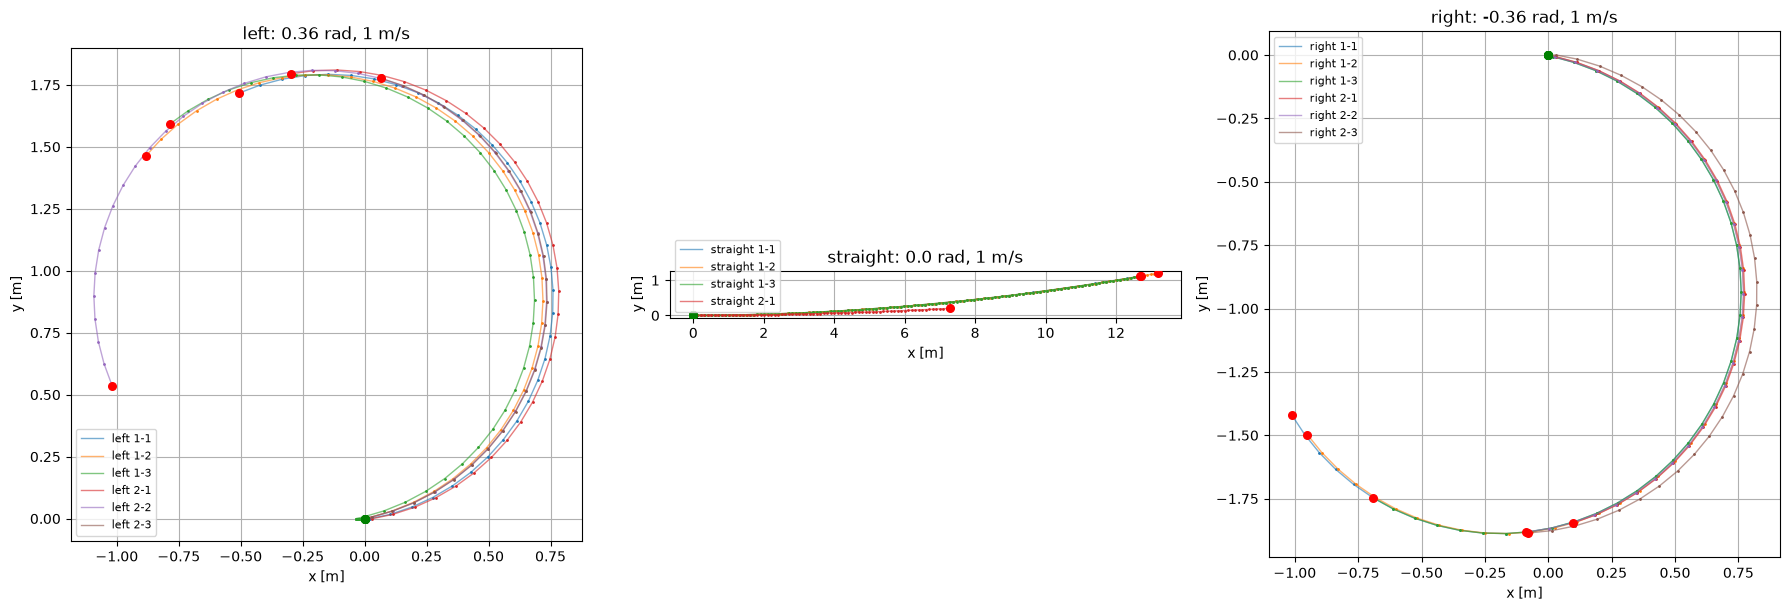

In [72]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

rootdir = "data-sim/"
n = 1
groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}

def load_sim(path, topic="/odom"):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for schema, channel, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p = msg.pose.pose.position          # Odometry: one level deeper than PoseStamped
            q = msg.pose.pose.orientation
            v = msg.twist.twist.linear
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,  # sim time
                "t_log": message.log_time / 1e9,                               # recording time
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
                "vx": v.x, "vy": v.y,
            })
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return df.sort_values("t").drop_duplicates(subset="t").reset_index(drop=True)

def normalize_start(df):
    # shift so the run starts at (0, 0) and rotate so it starts heading in +x
    x0, y0 = df["px"].iloc[0], df["py"].iloc[0]
    qx, qy, qz, qw = df[["qx", "qy", "qz", "qw"]].iloc[0]
    yaw0 = np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))

    dx, dy = df["px"] - x0, df["py"] - y0
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    df = df.copy()
    df["px"] = c * dx - s * dy
    df["py"] = s * dx + c * dy
    return df

dfs = {g: {} for g in groups}
for subdir, dirs, files in os.walk(rootdir):
    for file in files:
        if not file.endswith(".mcap"):
            continue
        name = os.path.splitext(file)[0]

        m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)", name)
        if not m:
            continue
        group, run = m.group(1), m.group(2)

        df = load_sim(os.path.join(subdir, file))
        if df.empty:
            print(f"{name}: no /odom messages, skipped")
            continue
        print(f"{name}: {len(df)} Msg")
        dfs[group][run] = normalize_start(df)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10.colors

for ax, group in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[group])):
        df = dfs[group][run]
        c = colors[i % len(colors)]
        ax.plot(df["px"], df["py"], "-", color=c, linewidth=1, alpha=0.6, label=f"{group} {run}")
        ax.plot(df["px"][::n], df["py"][::n], "o", color=c, markersize=1)
        ax.scatter(df["px"].iloc[0], df["py"].iloc[0], color="green", s=30, zorder=3)
        ax.scatter(df["px"].iloc[-1], df["py"].iloc[-1], color="red", s=30, zorder=3)

    ax.set_title(titles[group])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    if dfs[group]:
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

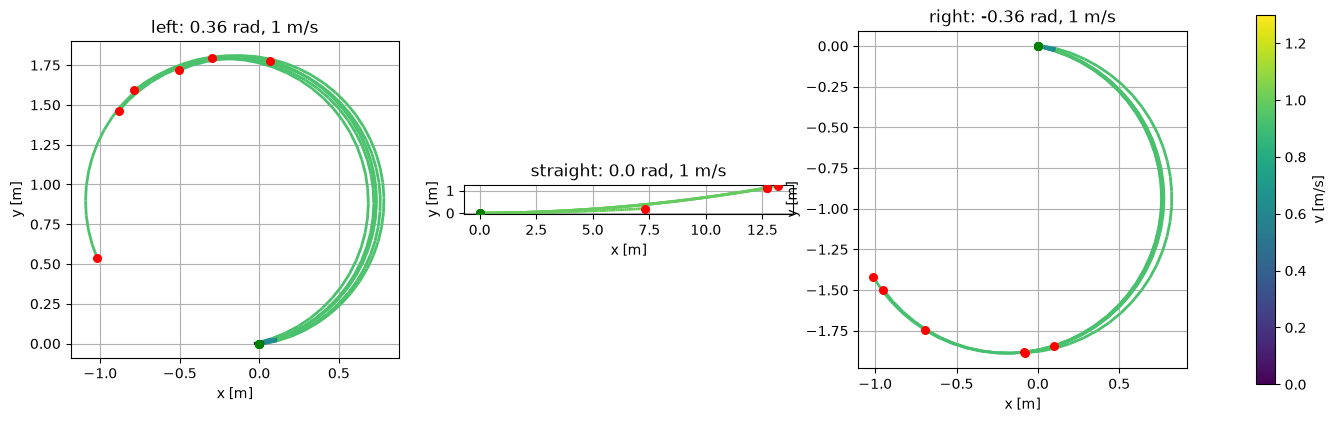

In [73]:
vmax_plot = 1.3  # upper limit of the color scale [m/s]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
lc = None
for ax, g in zip(axes, groups):
    for run in sorted(dfs[g]):
        df = dfs[g][run]
        x, y = df["px"].to_numpy(), df["py"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry

        segs = np.stack([np.column_stack([x[:-1], y[:-1]]),
                         np.column_stack([x[1:], y[1:]])], axis=1)
        lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, vmax_plot), linewidth=2)
        lc.set_array(v[:-1])
        ax.add_collection(lc)
        ax.scatter(x[0], y[0], color="green", s=30, zorder=3)
        ax.scatter(x[-1], y[-1], color="red", s=30, zorder=3)

    ax.autoscale()
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_aspect("equal"); ax.grid(True)

if lc is not None:
    fig.colorbar(lc, ax=axes, label="v [m/s]", shrink=0.8)
plt.show()

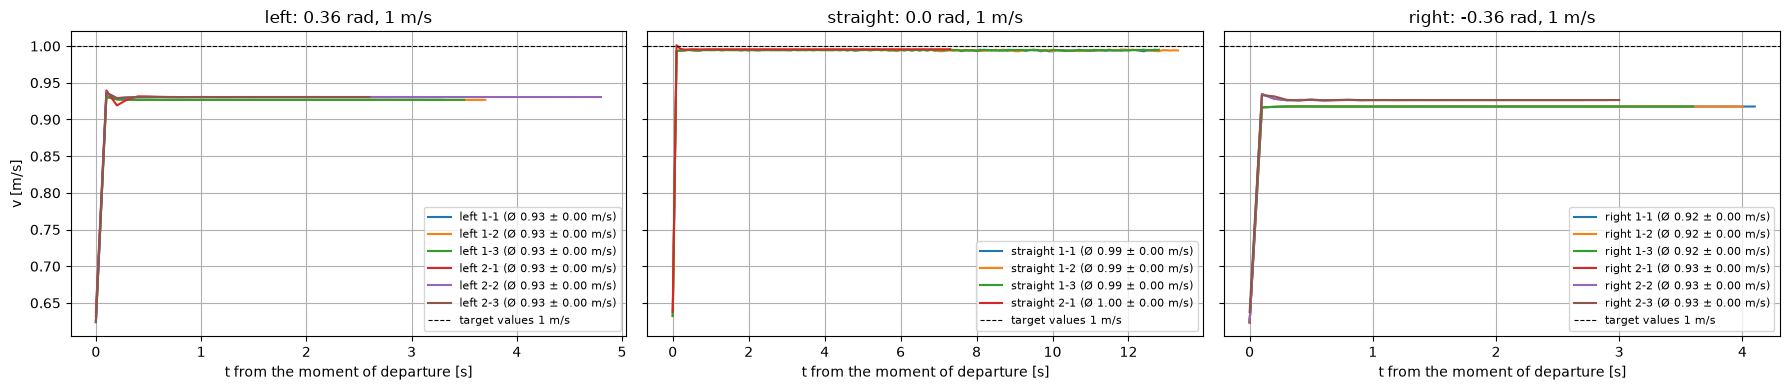

In [74]:
v_min = 0.5      
colors = plt.cm.tab10.colors

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t = df["t"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()  

        idx = np.flatnonzero(v > v_min)
        if idx.size == 0:
            print(f"{g} {run}: nie schneller als {v_min} m/s, übersprungen")
            continue
        t, v = t[idx[0]:idx[-1] + 1], v[idx[0]:idx[-1] + 1]

        steady = (t - t[0] > 0.7) & (t < t[-1] - 0.3)
        if steady.any():
            label = f"{g} {run} (Ø {v[steady].mean():.2f} ± {v[steady].std():.2f} m/s)"
        else:
            label = f"{g} {run}"

        ax.plot(t - t[0], v, color=colors[i % len(colors)], label=label)

    ax.axhline(1.0, color="k", ls="--", lw=0.8, label="target values 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

stage-1-test-left-1-1: no axle frames in TF, skipped
stage-1-test-left-1-2: no axle frames in TF, skipped
stage-1-test-left-1-3: no axle frames in TF, skipped
stage-1-test-right-1-1: no axle frames in TF, skipped
stage-1-test-right-1-2: no axle frames in TF, skipped
stage-1-test-right-1-3: no axle frames in TF, skipped
stage-1-test-straight-1-1: no axle frames in TF, skipped
stage-1-test-straight-1-2: no axle frames in TF, skipped
stage-1-test-straight-1-3: no axle frames in TF, skipped

Steady-state mean speed [m/s]:
   group run  /odom twist  Chassis (TF)  rear axle (TF)  front axle (TF)
    left 2-1        0.931         0.925           0.909            0.968
    left 2-2        0.931         0.925           0.909            0.968
    left 2-3        0.931         0.925           0.909            0.968
straight 2-1        0.996         0.997           0.997            0.997
   right 2-1        0.926         0.923           0.910            0.964
   right 2-2        0.926         0.92

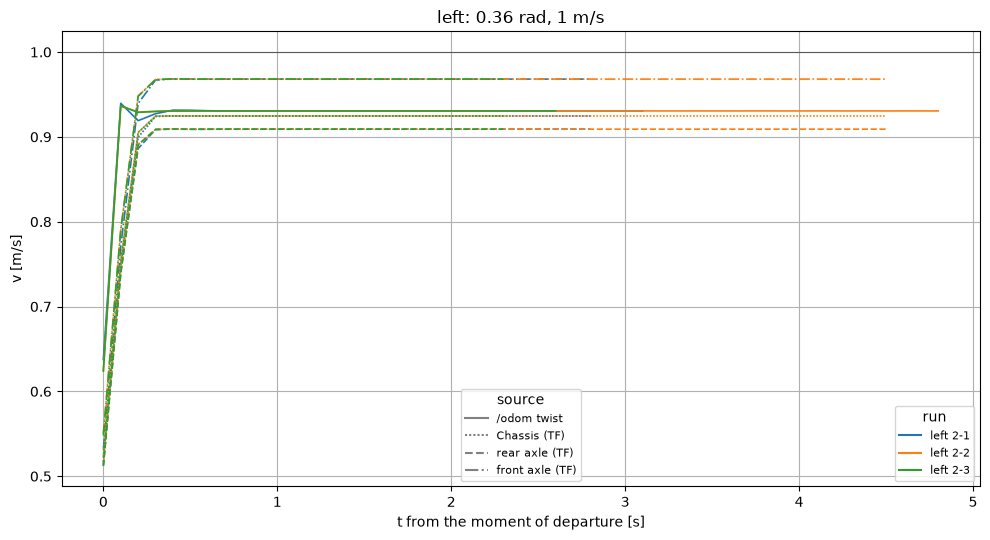

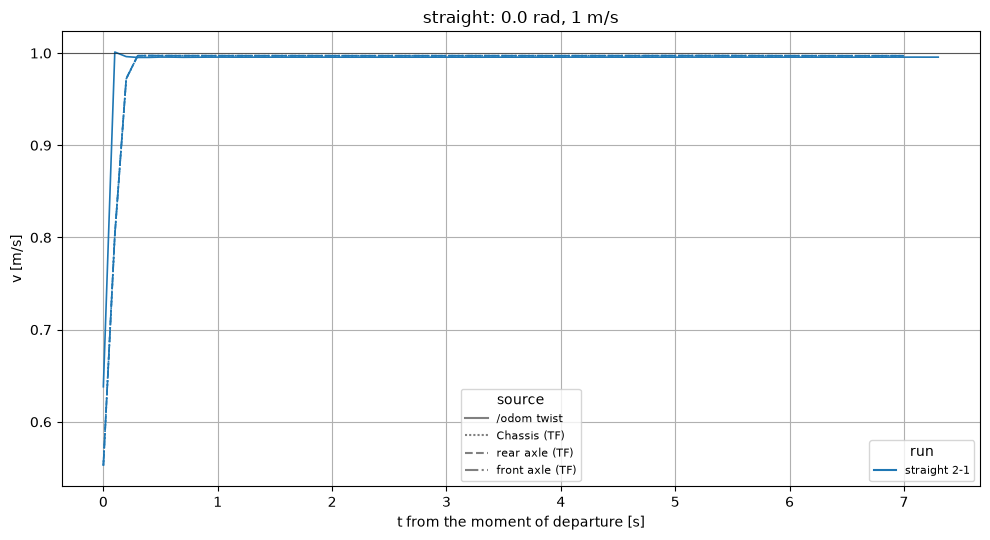

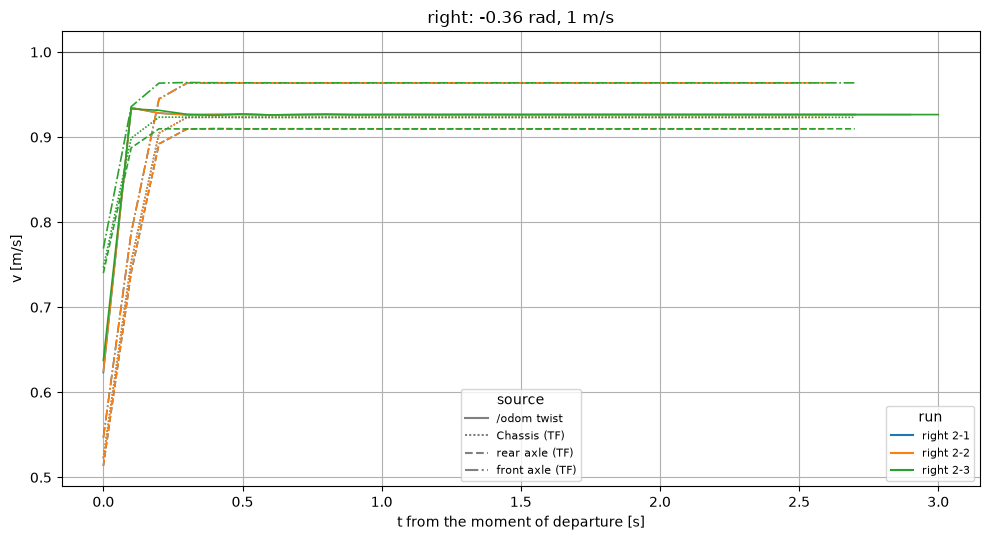

In [75]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory


rootdir = "data-sim/"
try:   # when run as a script, look for the data next to the script
    rootdir = os.path.join(os.path.dirname(os.path.abspath(__file__)), rootdir)
except NameError:
    pass  # in a notebook, the notebook folder is used

# Positions are expressed in this frame. world -> odom is fixed in our recordings,
# so measuring in "odom" gives the same speeds and avoids that extra link.
FIXED_FRAME = "odom"
MOVING_FRAME = "Chassis"            # its TF stamp defines the time of each sample
POINTS = ["Chassis", "back_axle", "front_axle"]

groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}

v_min = 0.5   # below this speed (at start/end) the car counts as standing still
K = 2         # half window (in samples) for TF speeds: distance over 2K samples
colors = plt.cm.tab10.colors

# How each source is drawn: key -> (label, line style)
SOURCES = {
    "odom":       ("/odom twist",        "-"),
    "Chassis":    ("Chassis (TF)",       (0, (1, 1))),
    "back_axle":  ("rear axle (TF)",     "--"),
    "front_axle": ("front axle (TF)",    "-."),
}


def stamp(header):
    return header.stamp.sec + header.stamp.nanosec * 1e-9


def clean(name):
    return name.lstrip("/")


def tf_matrix(tr):
    """geometry_msgs/Transform -> 4x4 matrix (parent <- child)."""
    t, q = tr.translation, tr.rotation
    x, y, z, w = q.x, q.y, q.z, q.w
    n = np.sqrt(x * x + y * y + z * z + w * w)
    # Normalize: a non-unit quaternion would scale positions instead of only rotating
    x, y, z, w = (0.0, 0.0, 0.0, 1.0) if n == 0 else (x / n, y / n, z / n, w / n)
    T = np.eye(4)
    T[:3, :3] = [
        [1 - 2 * (y * y + z * z), 2 * (x * y - z * w),     2 * (x * z + y * w)],
        [2 * (x * y + z * w),     1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
        [2 * (x * z - y * w),     2 * (y * z + x * w),     1 - 2 * (x * x + y * y)],
    ]
    T[:3, 3] = [t.x, t.y, t.z]
    return T


def pose_in(frame, target, edges):
    """Pose of `frame` in `target`: walk up the tree child -> parent and
    multiply the transforms. None if the frames are not connected."""
    T = np.eye(4)
    seen = set()
    while frame != target:
        if frame not in edges or frame in seen:
            return None
        seen.add(frame)
        parent, M = edges[frame]
        T = M @ T
        frame = parent
    return T


def speed_from_positions(t, x, y):
    """Central difference over 2K samples: distance / time."""
    if len(t) <= 2 * K:
        return np.array([]), np.array([])
    dist = np.hypot(x[2 * K:] - x[:-2 * K], y[2 * K:] - y[:-2 * K])
    return t[K:-K], dist / (t[2 * K:] - t[:-2 * K])


def load_run(path):
    """Return {source: (t, v)} for one recording:
    'odom' from the /odom twist, the others from TF positions."""
    edges = {}                  # child -> (parent, 4x4)
    odom = {}                   # stamp -> speed
    pos = {}                    # stamp -> {point: (x, y)}
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, channel, _, msg in reader.iter_decoded_messages(
                topics=["/odom", "/tf", "/tf_static"]):
            if channel.topic == "/odom":
                v = msg.twist.twist.linear
                odom[stamp(msg.header)] = np.hypot(v.x, v.y)
                continue

            t_chassis = None
            for tr in msg.transforms:
                child = clean(tr.child_frame_id)
                edges[child] = (clean(tr.header.frame_id), tf_matrix(tr.transform))
                if child == MOVING_FRAME:
                    t_chassis = stamp(tr.header)

            # Only sample when the chassis moved, so other /tf publishers
            # (wheels, suspension) cannot distort the time axis
            if channel.topic != "/tf" or t_chassis is None:
                continue
            row = {}
            for p in POINTS:
                T = pose_in(p, FIXED_FRAME, edges)
                if T is None:
                    break
                row[p] = (T[0, 3], T[1, 3])
            else:
                pos[t_chassis] = row

    out = {}
    if odom:
        t = np.array(sorted(odom))
        out["odom"] = (t, np.array([odom[k] for k in t]))
    if pos:
        t = np.array(sorted(pos))
        for p in POINTS:
            xy = np.array([pos[k][p] for k in t])
            out[p] = speed_from_positions(t, xy[:, 0], xy[:, 1])
    return out


def trim(t, v):
    """Cut off standstill at start and end; time starts at departure."""
    idx = np.flatnonzero(v > v_min)
    if idx.size == 0:
        return None
    t, v = t[idx[0]:idx[-1] + 1], v[idx[0]:idx[-1] + 1]
    return t - t[0], v


def steady_mean(t, v):
    """Mean in the steady part (skip acceleration and the last samples)."""
    steady = (t > 0.7) & (t < t[-1] - 0.3)
    return v[steady].mean() if steady.any() else np.nan


runs = {g: {} for g in groups}
for subdir, _, files in os.walk(rootdir):
    for file in files:
        name, ext = os.path.splitext(file)
        if ext != ".mcap" or not name.startswith("stage-1-test"):
            continue
        m = re.search(r"(left|straight|right)-(\d+(?:-\d+)*)", name)
        if not m:
            continue
        data = load_run(os.path.join(subdir, file))
        if "back_axle" not in data:
            print(f"{name}: no axle frames in TF, skipped")
            continue
        runs[m.group(1)][m.group(2)] = data


summary = []
for g in groups:
    if not runs[g]:
        continue
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for i, run in enumerate(sorted(runs[g])):
        c = colors[i % len(colors)]          # one color per run
        row = {"group": g, "run": run}
        for key, (label, style) in SOURCES.items():
            if key not in runs[g][run]:
                continue
            res = trim(*runs[g][run][key])
            if res is None:
                continue
            t, v = res
            row[label] = steady_mean(t, v)
            ax.plot(t, v, linestyle=style, color=c, lw=1.2)
        summary.append(row)

    ax.axhline(1.0, color="k", lw=0.8, alpha=0.5)

    # Two legends: colors = runs, line styles = measuring points
    run_handles = [Line2D([], [], color=colors[i % len(colors)], label=f"{g} {run}")
                   for i, run in enumerate(sorted(runs[g]))]
    style_handles = [Line2D([], [], color="gray", linestyle=style, label=label)
                     for label, style in SOURCES.values()]
    leg = ax.legend(handles=run_handles, loc="lower right", fontsize=8, title="run")
    ax.add_artist(leg)
    ax.legend(handles=style_handles, loc="lower center", fontsize=8, title="source")

    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.set_ylabel("v [m/s]")
    ax.grid(True)
    fig.tight_layout()

# Steady-state means per run and source
summary = pd.DataFrame(summary)
print("\nSteady-state mean speed [m/s]:")
print(summary.round(3).to_string(index=False))

plt.show()   # shows all three figures

##### Check on Sim Speed

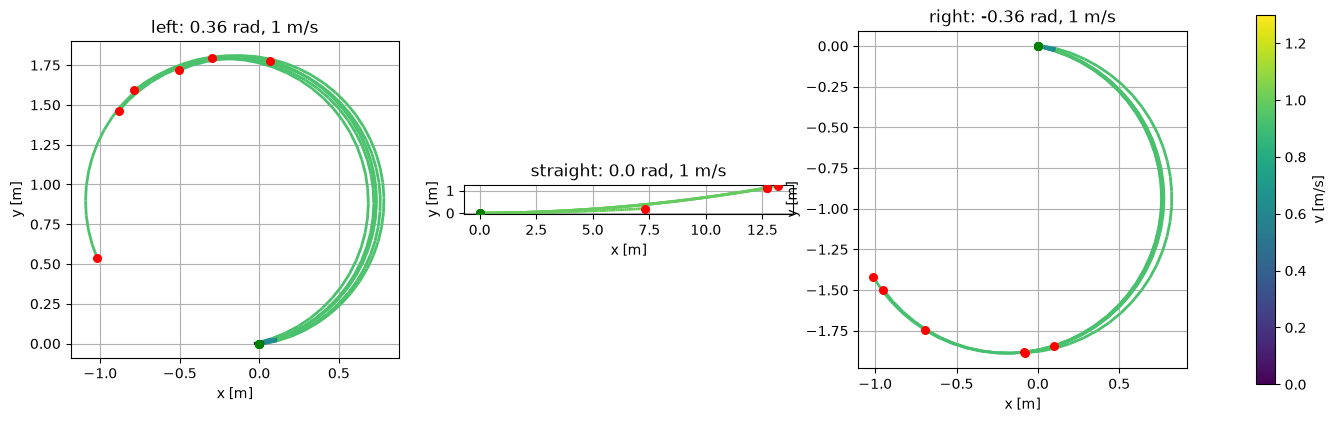

In [76]:
vmax_plot = 1.3  # upper limit of the color scale [m/s]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
lc = None
for ax, g in zip(axes, groups):
    for run in sorted(dfs[g]):
        df = dfs[g][run]
        x, y = df["px"].to_numpy(), df["py"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry

        segs = np.stack([np.column_stack([x[:-1], y[:-1]]),
                         np.column_stack([x[1:], y[1:]])], axis=1)
        lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, vmax_plot), linewidth=2)
        lc.set_array(v[:-1])
        ax.add_collection(lc)
        ax.scatter(x[0], y[0], color="green", s=30, zorder=3)
        ax.scatter(x[-1], y[-1], color="red", s=30, zorder=3)

    ax.autoscale()
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    ax.set_aspect("equal"); ax.grid(True)

if lc is not None:
    fig.colorbar(lc, ax=axes, label="v [m/s]", shrink=0.8)
plt.show()

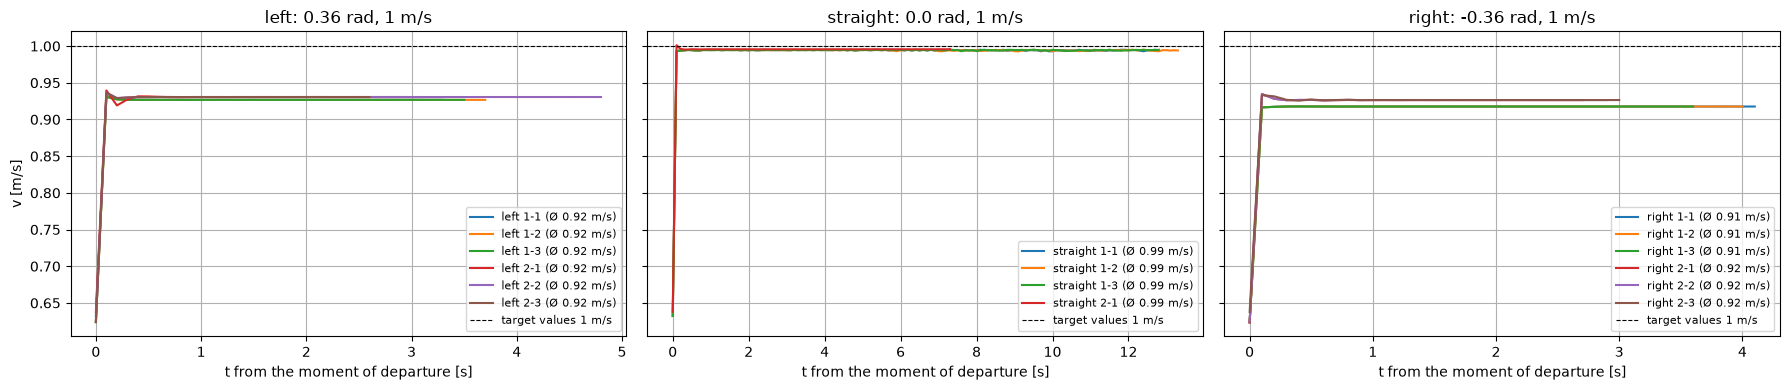

In [77]:
v_min = 0.5

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t = df["t"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry

        idx = np.flatnonzero(v > v_min)               # cut standstill at start and end
        if len(idx) == 0:
            print(f"{g} {run}: never faster than {v_min} m/s, skipped")
            continue
        v, t = v[idx[0]:idx[-1] + 1], t[idx[0]:idx[-1] + 1]

        ax.plot(t - t[0], v, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v[v > v_min].mean():.2f} m/s)")

    ax.axhline(1.0, color="k", ls="--", lw=0.8, label="target values 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

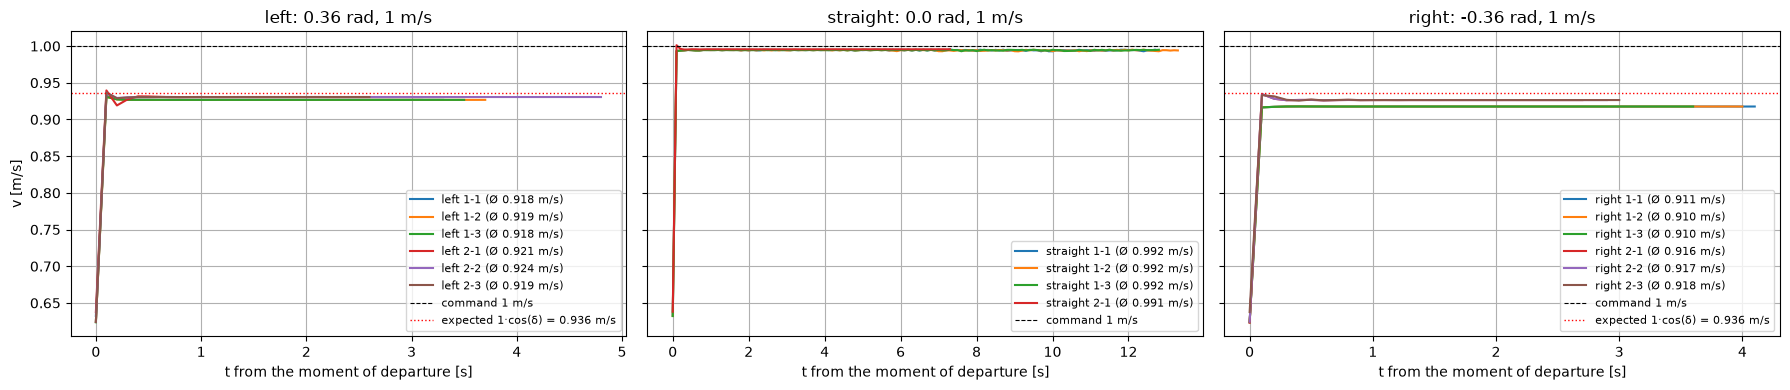

In [78]:
v_min = 0.5
v_cmd = 1.0                                    # input speed in the simulation
deltas = {"left": 0.36, "straight": 0.0, "right": -0.36}
convert_to_front = False                       # True: speed converted to the front wheel (v / cos δ)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    c = np.cos(deltas[g])

    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t = df["t"].to_numpy()
        v = np.hypot(df["vx"], df["vy"]).to_numpy()   # speed directly from odometry
        if convert_to_front:
            v = v / c

        idx = np.flatnonzero(v > v_min)               # cut standstill at start and end
        if len(idx) == 0:
            print(f"{g} {run}: never faster than {v_min} m/s, skipped")
            continue
        v, t = v[idx[0]:idx[-1] + 1], t[idx[0]:idx[-1] + 1]

        ax.plot(t - t[0], v, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v[v > v_min].mean():.3f} m/s)")

    ax.axhline(v_cmd, color="k", ls="--", lw=0.8, label=f"command {v_cmd:.0f} m/s")
    if not convert_to_front and deltas[g] != 0:
        ax.axhline(v_cmd * c, color="r", ls=":", lw=1.0,
                   label=f"expected 1·cos(δ) = {v_cmd * c:.3f} m/s")

    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel("v [m/s]")
plt.tight_layout()
plt.show()

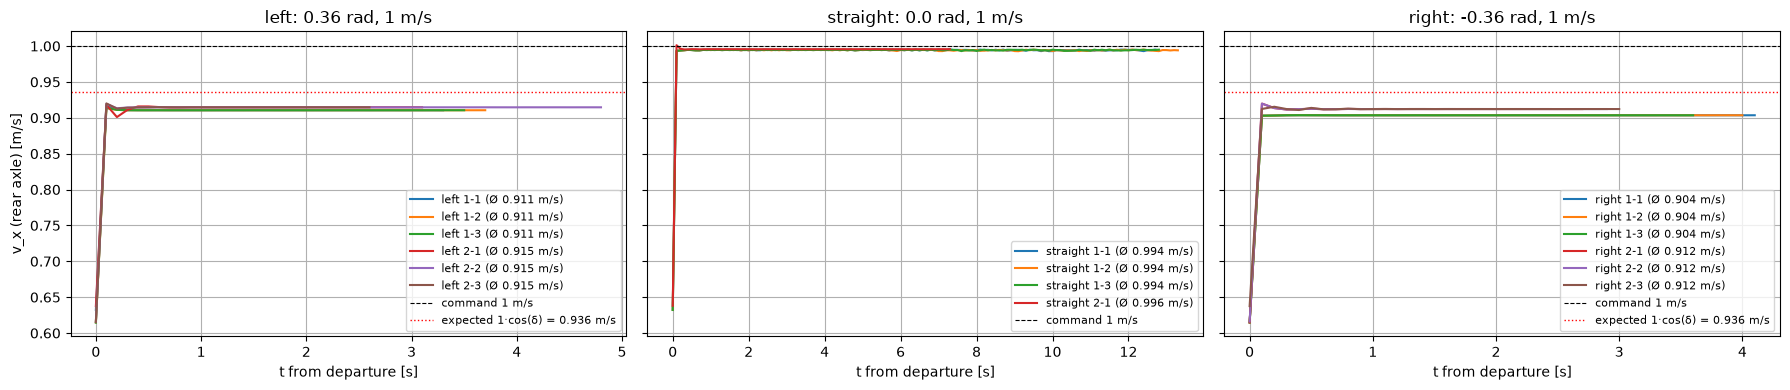

In [79]:
L = 0.320                 # Radstand Leatherback laut Isaac-Sim-Doku
v_min, t_settle = 0.5, 0.5
v_cmd = 1.0
deltas = {"left": 0.36, "straight": 0.0, "right": -0.36}

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, g in zip(axes, groups):
    c = np.cos(deltas[g])
    for i, run in enumerate(sorted(dfs[g])):
        df = dfs[g][run]
        t  = df["t"].to_numpy()
        vx = df["vx"].to_numpy()          # Body-Frame!
        idx = np.flatnonzero(np.abs(vx) > v_min)
        if len(idx) == 0:
            continue
        sl = slice(idx[0], idx[-1] + 1)
        t, vx = t[sl] - t[idx[0]], vx[sl]

        ss = t > t_settle                 # nur stationärer Teil
        v_mean = np.trapezoid(vx[ss], t[ss]) / (t[ss][-1] - t[ss][0])
        
        info = ""
        if "wz" in df and deltas[g] != 0:
            wz = df["wz"].to_numpy()[sl]
            d_eff = np.arctan(np.mean(wz[ss]) * L / v_mean)
            info = f", δ_eff {d_eff:+.3f} rad"

        ax.plot(t, vx, color=colors[i % len(colors)],
                label=f"{g} {run} (Ø {v_mean:.3f} m/s{info})")

    ax.axhline(v_cmd, color="k", ls="--", lw=0.8, label=f"command {v_cmd:g} m/s")
    if deltas[g] != 0:
        ax.axhline(v_cmd * c, color="r", ls=":", lw=1.0,
                   label=f"expected {v_cmd:g}·cos(δ) = {v_cmd * c:.3f} m/s")
    ax.set_title(titles[g]); ax.set_xlabel("t from departure [s]")
    ax.grid(True); ax.legend(fontsize=8)
axes[0].set_ylabel("v_x (rear axle) [m/s]")
plt.tight_layout(); plt.show()

### Check on Sim-Path and Real-Path

In [80]:
def load_all(rootdir, loader, clean=None):
    out = {g: {} for g in groups}
    for subdir, dirs, files in os.walk(rootdir):
        for file in files:
            if not file.endswith(".mcap"):
                continue
            name = os.path.splitext(file)[0]
            m = re.search(r"(left|straight|right)-(\d+)", name)
            if not m:
                continue
            group, run = m.group(1), int(m.group(2))

            df = loader(os.path.join(subdir, file))
            if clean is not None:
                df = clean(df)
            if df.empty:
                print(f"{rootdir}{name}: empty, skipped")
                continue
            out[group][run] = normalize_start(df)
    return out

dfs_real = load_all("data-real/", load_vicon, clean=lambda d: remove_jumps(d, max_speed=5.0))
dfs_sim  = load_all("data-sim/",  load_sim)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, groups):
    for j, run in enumerate(sorted(dfs_real[g])):
        df = dfs_real[g][run]
        ax.plot(df["px"], df["py"], "-", color="tab:blue", lw=1.2, alpha=0.6,
                label="real (Vicon)" if j == 0 else None)

    for j, run in enumerate(sorted(dfs_sim[g])):
        df = dfs_sim[g][run]
        ax.plot(df["px"], df["py"], "--", color="tab:orange", lw=1.5, alpha=0.9,
                label="sim (odom)" if j == 0 else None)

    ax.scatter(0, 0, color="green", s=40, zorder=3, label="start")
    ax.set_title(titles[g])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

TypeError: load_vicon() missing 1 required positional argument: 'topic'

### Error 